
# FitzHugh–Nagumo Neural Dynamics + Kernel Koopman Transient Spikes

This is the **third neuroscience dynamical-system experiment**.

The kernel/KEDMD framework is unchanged. Only the underlying neural dynamics change.

We use the standard two-variable FitzHugh–Nagumo form

\[
\dot v = v-\frac{v^3}{3}-w+I_{\rm ext},
\]

\[
\dot w = \varepsilon(v+a-bw),
\]

where

- \(v\) is the fast voltage-like/excitability variable,
- \(w\) is the slow recovery/refractory variable.

For this controlled benchmark we use

\[
a=0.7,\qquad
b=0.8,\qquad
\varepsilon=0.08,\qquad
I_{\rm ext}=0.10.
\]

This parameter set is chosen to give a **stable excitable equilibrium** with a damped
finite-time response. It is a controlled dynamical benchmark, not a claim of a unique
biophysical parameterization.

The experiment keeps the original regularized KEDMD construction

\[
A_\lambda=(G_X+\lambda I)^{-1}A_X,
\]

with

\[
\widetilde A_\lambda
=
G_\lambda^{1/2}A_\lambda G_\lambda^{-1/2}
=
G_\lambda^{-1/2}A_XG_\lambda^{-1/2},
\]

and the transient diagnostic

\[
\|A_\lambda^n\|_{G_\lambda}
=
\|\widetilde A_\lambda^n\|_2.
\]

We compare:

1. exact local physical transient gain;
2. finite-amplitude nonlinear perturbation gain;
3. Laplace, Matérn-\(3/2\), RQ and RBF KEDMD transient envelopes;
4. fixed worst-direction growth;
5. Koopman surrogate pseudospectra;
6. grid-based Kreiss estimates;
7. regularization sensitivity.


In [1]:

# Optional only if packages are missing:
!pip3 install -U numpy scipy pandas matplotlib



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import root
from scipy.linalg import expm, eigh, solve, svdvals
from scipy.spatial.distance import cdist

np.set_printoptions(precision=6, suppress=True)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
SEED = 42

# Physical time stepping
DT = 0.10
N_SUBSTEPS = 8
T_TRANSIENT = 100

# Local training region
TRAIN_RADIUS = 0.30

# KEDMD regularization
LAMBDA = 3e-3

# Pseudospectral calculation
FAST_MODE = True

if FAST_MODE:
    M = 80
    GRID_N = 61
else:
    M = 120
    GRID_N = 101

GRID_LIM = 1.30
EPS_LEVELS = (1e-2, 1e-3)

OUTDIR = "FHN_kernel_koopman_results"
os.makedirs(OUTDIR, exist_ok=True)

print("FAST_MODE =", FAST_MODE)
print("M =", M)
print("lambda =", LAMBDA)
print("DT =", DT)
print("transient horizon =", T_TRANSIENT)
print("pseudospectral grid =", GRID_N, "x", GRID_N)


FAST_MODE = True
M = 80
lambda = 0.003
DT = 0.1
transient horizon = 100
pseudospectral grid = 61 x 61



## 1. FitzHugh–Nagumo system and stable equilibrium


In [3]:

# ------------------------------------------------------------
# FitzHugh-Nagumo parameters
# ------------------------------------------------------------
a = 0.7
b = 0.8
eps = 0.08
I_ext = 0.10


def fhn_rhs(x):
    v, w = np.asarray(x)

    dv = v - (v ** 3) / 3.0 - w + I_ext
    dw = eps * (v + a - b * w)

    return np.array([dv, dw])


def fhn_jacobian(x):
    v, w = np.asarray(x)

    return np.array([
        [1.0 - v ** 2, -1.0],
        [eps, -eps * b],
    ])


sol = root(
    fhn_rhs,
    x0=np.array([-1.0, -0.5]),
)

if not sol.success:
    raise RuntimeError(sol.message)

x_eq = sol.x
J_star = fhn_jacobian(x_eq)
eig_J = np.linalg.eigvals(J_star)

departure_J = np.linalg.norm(
    J_star.T @ J_star
    - J_star @ J_star.T,
    ord="fro",
)

print("Equilibrium x* = [v*, w*] =", x_eq)
print("Residual ||f(x*)|| =", np.linalg.norm(fhn_rhs(x_eq)))

print("\nJacobian J* =")
print(J_star)

print("\neigenvalues(J*) =", eig_J)
print("max Re eigenvalue =", np.max(np.real(eig_J)))
print("departure from normality =", departure_J)

if np.max(np.real(eig_J)) >= 0:
    raise RuntimeError("Chosen FHN equilibrium is not asymptotically stable.")


Equilibrium x* = [v*, w*] = [-1.137512 -0.54689 ]
Residual ||f(x*)|| = 2.498001805406602e-16

Jacobian J* =
[[-0.293934 -1.      ]
 [ 0.08     -0.064   ]]

eigenvalues(J*) = [-0.178967+0.258423j -0.178967-0.258423j]
max Re eigenvalue = -0.178967035273972
departure from normality = 1.4483840312693719



## 2. Exact local physical transient and nonlinear perturbation response

The tangent dynamics at the stable equilibrium are

\[
\delta\dot x=J_\star\delta x,
\]

so

\[
g_{\rm local}(t)
=
\|e^{J_\star t}\|_2
\]

is available exactly.

We also perturb the nonlinear system in many directions around the equilibrium and
measure

\[
g_{\rm nonlinear}(t)
=
\max_{\|q\|_2=1}
\frac{
\|\Phi_t(x_\star+\delta q)-x_\star\|_2
}{
\delta
}.
\]


In [4]:

def fhn_rhs_batch(X):
    X = np.asarray(X)

    v = X[:, 0]
    w = X[:, 1]

    dv = v - (v ** 3) / 3.0 - w + I_ext
    dw = eps * (v + a - b * w)

    return np.column_stack([dv, dw])


def rk4_batch(X, h):
    k1 = fhn_rhs_batch(X)
    k2 = fhn_rhs_batch(X + 0.5 * h * k1)
    k3 = fhn_rhs_batch(X + 0.5 * h * k2)
    k4 = fhn_rhs_batch(X + h * k3)

    return X + (h / 6.0) * (
        k1 + 2.0 * k2 + 2.0 * k3 + k4
    )


def flow_batch(
    X,
    delta_t=DT,
    n_substeps=N_SUBSTEPS,
):
    Y = np.asarray(X, dtype=float).copy()

    h = delta_t / n_substeps

    for _ in range(n_substeps):
        Y = rk4_batch(Y, h)

    return Y


In [5]:

steps = np.arange(T_TRANSIENT + 1)
times = DT * steps

# Exact local tangent transient
gain_local = np.array([
    svdvals(expm(J_star * t))[0]
    for t in times
])

local_peak_index = int(np.argmax(gain_local))

# Finite-amplitude nonlinear perturbation transient
PERTURB_AMP = 1e-2
N_DIRECTIONS = 96

angles = np.linspace(
    0.0,
    2.0 * np.pi,
    N_DIRECTIONS,
    endpoint=False,
)

directions = np.column_stack([
    np.cos(angles),
    np.sin(angles),
])

Xpert = (
    x_eq[None, :]
    + PERTURB_AMP * directions
)

gain_nonlinear = np.zeros(
    T_TRANSIENT + 1
)

gain_nonlinear[0] = 1.0

for n in range(
    1,
    T_TRANSIENT + 1,
):
    Xpert = flow_batch(
        Xpert,
        delta_t=DT,
        n_substeps=N_SUBSTEPS,
    )

    deviations = (
        Xpert - x_eq[None, :]
    )

    gain_nonlinear[n] = np.max(
        np.linalg.norm(
            deviations,
            axis=1,
        )
        / PERTURB_AMP
    )

nonlinear_peak_index = int(
    np.argmax(gain_nonlinear)
)

print("Local tangent physical peak:")
print(f"  gain = {gain_local[local_peak_index]:.6f}")
print(f"  step = {local_peak_index}")
print(f"  time = {times[local_peak_index]:.6f}")

print("\nFinite-amplitude nonlinear peak:")
print(f"  gain = {gain_nonlinear[nonlinear_peak_index]:.6f}")
print(f"  step = {nonlinear_peak_index}")
print(f"  time = {times[nonlinear_peak_index]:.6f}")


Local tangent physical peak:
  gain = 1.710481
  step = 33
  time = 3.300000

Finite-amplitude nonlinear peak:
  gain = 1.747596
  step = 35
  time = 3.500000


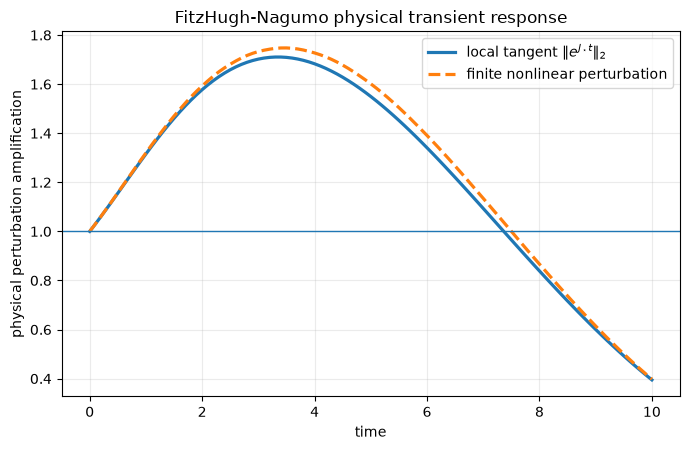

In [6]:

fig, ax = plt.subplots(
    figsize=(7.0, 4.6),
)

ax.plot(
    times,
    gain_local,
    linewidth=2.3,
    label=r"local tangent $\|e^{J_\star t}\|_2$",
)

ax.plot(
    times,
    gain_nonlinear,
    linewidth=2.3,
    linestyle="--",
    label="finite nonlinear perturbation",
)

ax.axhline(
    1.0,
    linewidth=1.0,
)

ax.set_xlabel("time")
ax.set_ylabel(
    "physical perturbation amplification"
)
ax.set_title(
    "FitzHugh-Nagumo physical transient response"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_physical_transient.png",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()



## 3. Local one-step snapshot pairs

We sample a neighborhood of the stable FHN equilibrium,

\[
x_i=x_\star+\delta_i,
\qquad
\delta_i\sim[-R,R]^2,
\]

then integrate exactly one discrete interval,

\[
y_i=\Phi_{\Delta t}(x_i).
\]

This avoids using a single decaying trajectory and gives the surrogate local state-space coverage.


In [7]:

rng = np.random.default_rng(SEED)

X = (
    x_eq[None, :]
    + rng.uniform(
        -TRAIN_RADIUS,
        TRAIN_RADIUS,
        size=(M, 2),
    )
)

Y = flow_batch(
    X,
    delta_t=DT,
    n_substeps=N_SUBSTEPS,
)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

print("v range:", X[:, 0].min(), X[:, 0].max())
print("w range:", X[:, 1].min(), X[:, 1].max())

print("\nFirst 3 snapshot pairs:")
for i in range(3):
    print(
        "x =", X[i],
        " -> y =", Y[i]
    )


X shape: (80, 2)
Y shape: (80, 2)
v range: -1.423884984866234 -0.8550934141096083
w range: -0.8424729240825845 -0.26151687495113424

First 3 snapshot pairs:
x = [-0.973139 -0.583563]  -> y = [-0.97145  -0.582012]
x = [-0.922353 -0.428469]  -> y = [-0.935726 -0.427562]
x = [-1.381006 -0.261517]  -> y = [-1.394345 -0.265333]



## 4. Same four kernel representations


In [8]:

KERNELS = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]


def pairwise_distance(
    A,
    B,
    metric="euclidean",
):
    return cdist(
        A,
        B,
        metric=metric,
    )


def median_scale(
    X,
    kind,
):
    metric = (
        "cityblock"
        if kind == "Laplace"
        else "euclidean"
    )

    D = pairwise_distance(
        X,
        X,
        metric=metric,
    )

    positive = D[D > 0]

    return float(
        np.median(positive)
    )


def kernel_matrix(
    A,
    B,
    kind,
    gamma,
):
    if kind == "Laplace":

        R = pairwise_distance(
            A,
            B,
            metric="cityblock",
        )

        return np.exp(
            -R / gamma
        )

    R = pairwise_distance(
        A,
        B,
        metric="euclidean",
    )

    if kind == "Matern32":

        q = (
            np.sqrt(3.0)
            * R
            / gamma
        )

        return (
            (1.0 + q)
            * np.exp(-q)
        )

    if kind == "RQ":

        return (
            1.0
            + (R ** 2)
            / (2.0 * gamma ** 2)
        ) ** (-1.0)

    if kind == "RBF":

        return np.exp(
            -(R ** 2)
            / (2.0 * gamma ** 2)
        )

    raise ValueError(kind)


for kind in KERNELS:
    print(
        f"{kind:10s} "
        f"gamma={median_scale(X, kind):.6f}"
    )


Laplace    gamma=0.367711
Matern32   gamma=0.293183
RQ         gamma=0.293183
RBF        gamma=0.293183



## 5. Original KEDMD construction


In [9]:

def spd_sqrt_and_invsqrt(
    G,
    floor=1e-14,
):
    Gs = 0.5 * (G + G.T)

    evals, U = eigh(Gs)

    evals = np.maximum(
        evals,
        floor,
    )

    Ghalf = (
        U * np.sqrt(evals)
    ) @ U.T

    Gmhalf = (
        U * (1.0 / np.sqrt(evals))
    ) @ U.T

    return Ghalf, Gmhalf


def build_kedmd(
    X,
    Y,
    kind,
    lam=LAMBDA,
):
    gamma = median_scale(
        X,
        kind,
    )

    GX = kernel_matrix(
        X,
        X,
        kind,
        gamma,
    )

    AX = kernel_matrix(
        Y,
        X,
        kind,
        gamma,
    )

    Glam = (
        GX
        + lam * np.eye(GX.shape[0])
    )

    A = solve(
        Glam,
        AX,
        assume_a="pos",
    )

    Ghalf, Gmhalf = (
        spd_sqrt_and_invsqrt(
            Glam
        )
    )

    Atilde_similarity = (
        Ghalf
        @ A
        @ Gmhalf
    )

    Atilde = (
        Gmhalf
        @ AX
        @ Gmhalf
    )

    identity_error = (
        np.linalg.norm(
            Atilde
            - Atilde_similarity,
            ord="fro",
        )
        / np.linalg.norm(
            Atilde,
            ord="fro",
        )
    )

    return {
        "kind": kind,
        "gamma": gamma,
        "GX": GX,
        "AX": AX,
        "Glam": Glam,
        "A": A,
        "Atilde": Atilde,
        "Ghalf": Ghalf,
        "Gmhalf": Gmhalf,
        "identity_error": identity_error,
    }


models = {
    kind: build_kedmd(
        X,
        Y,
        kind,
        lam=LAMBDA,
    )
    for kind in KERNELS
}

for kind in KERNELS:
    m = models[kind]

    print(
        f"{kind:10s} | "
        f"gamma={m['gamma']:.6f} | "
        f"identity error="
        f"{m['identity_error']:.3e}"
    )


Laplace    | gamma=0.367711 | identity error=1.813e-14
Matern32   | gamma=0.293183 | identity error=1.855e-13
RQ         | gamma=0.293183 | identity error=5.673e-13
RBF        | gamma=0.293183 | identity error=7.231e-13



## 6. KEDMD transient amplification and fixed worst direction


In [10]:

def transient_diagnostics(
    Atilde,
    T=T_TRANSIENT,
):
    d = Atilde.shape[0]

    env = np.zeros(T + 1)
    env[0] = 1.0

    powers = [np.eye(d)]

    Pmat = np.eye(d)

    for n in range(
        1,
        T + 1,
    ):
        Pmat = (
            Pmat @ Atilde
        )

        powers.append(
            Pmat.copy()
        )

        env[n] = (
            svdvals(Pmat)[0]
        )

    t_peak = int(
        np.argmax(env[1:])
        + 1
    )

    peak = float(
        env[t_peak]
    )

    _, _, Vh = np.linalg.svd(
        powers[t_peak],
        full_matrices=False,
    )

    y_star = Vh[0, :]
    y_star /= np.linalg.norm(
        y_star
    )

    fixed = np.zeros(T + 1)
    fixed[0] = 1.0

    for n in range(
        1,
        T + 1,
    ):
        fixed[n] = np.linalg.norm(
            powers[n] @ y_star
        )

    rho = float(
        np.max(
            np.abs(
                np.linalg.eigvals(
                    Atilde
                )
            )
        )
    )

    departure_normality = float(
        np.linalg.norm(
            Atilde.conj().T
            @ Atilde
            - Atilde
            @ Atilde.conj().T,
            ord="fro",
        )
    )

    return {
        "env": env,
        "fixed": fixed,
        "t_peak": t_peak,
        "peak": peak,
        "rho": rho,
        "departure_normality": departure_normality,
    }


for kind in KERNELS:

    models[kind][
        "transient"
    ] = transient_diagnostics(
        models[kind]["Atilde"],
        T=T_TRANSIENT,
    )


In [11]:

rows = []

for kind in KERNELS:

    m = models[kind]
    td = m["transient"]

    rows.append({
        "kernel": kind,
        "gamma": m["gamma"],
        "cond_Glambda": np.linalg.cond(
            m["Glam"]
        ),
        "rho_Atilde": td["rho"],
        "departure_normality": td[
            "departure_normality"
        ],
        "peak_G": td["peak"],
        "t_peak": td["t_peak"],
        "peak_time": td["t_peak"] * DT,
    })

transient_table = pd.DataFrame(
    rows
)

display(transient_table)

transient_table.to_csv(
    os.path.join(
        OUTDIR,
        "FHN_transient_summary.csv",
    ),
    index=False,
)


,kernel,gamma,cond_Glambda,rho_Atilde,departure_normality,peak_G,t_peak,peak_time
0,Laplace,0.367711,1432.873264,0.999960,2.180364,1.685853,12,1.2
1,Matern32,0.293183,13382.781427,1.000365,0.710038,2.338868,28,2.8
2,RQ,0.293183,18128.800051,1.000345,0.387654,2.583696,30,3.0
3,RBF,0.293183,16357.547378,1.000606,0.322007,3.437277,32,3.2


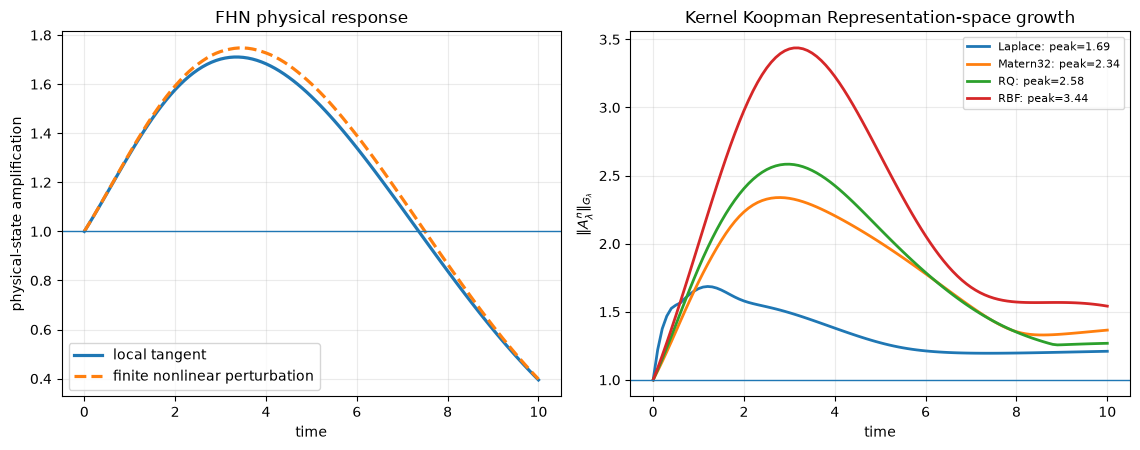

In [12]:

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.6),
)

# Physical dynamics
axes[0].plot(
    times,
    gain_local,
    linewidth=2.3,
    label="local tangent",
)

axes[0].plot(
    times,
    gain_nonlinear,
    linewidth=2.3,
    linestyle="--",
    label="finite nonlinear perturbation",
)

axes[0].axhline(
    1.0,
    linewidth=1.0,
)

axes[0].set_xlabel("time")
axes[0].set_ylabel(
    "physical-state amplification"
)

axes[0].set_title(
    "FHN physical response"
)

axes[0].grid(alpha=0.25)
axes[0].legend()

# KEDMD geometry
for kind in KERNELS:

    td = models[kind]["transient"]

    axes[1].plot(
        times,
        td["env"],
        linewidth=2.0,
        label=(
            f"{kind}: "
            f"peak={td['peak']:.2f}"
        ),
    )

axes[1].axhline(
    1.0,
    linewidth=1.0,
)

axes[1].set_xlabel("time")

axes[1].set_ylabel(
    r"$\|A_\lambda^n\|_{G_\lambda}$"
)

axes[1].set_title(
    "Kernel Koopman Representation-space growth"
)

axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_physical_vs_KEDMD_transient.pdf",
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.show()


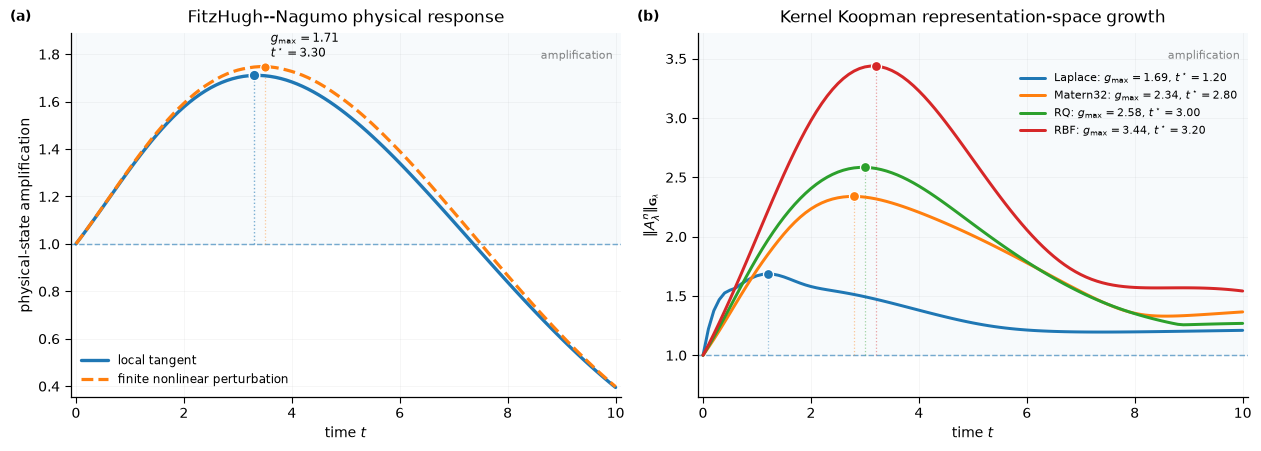

In [17]:
# Convert discrete Koopman steps to physical time
times = steps * DT

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.4),
    constrained_layout=True
)


# ============================================================
# Common visual treatment
# ============================================================

def clean_axis(ax):

    # Do NOT touch font settings
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.9)
    ax.spines["bottom"].set_linewidth(0.9)

    ax.tick_params(
        direction="out",
        length=4,
        width=0.8
    )

    ax.grid(
        True,
        linewidth=0.55,
        alpha=0.15
    )

    ax.set_axisbelow(True)


# ============================================================
# LEFT: FitzHugh-Nagumo physical response
# ============================================================

ax = axes[0]


# ------------------------------------------------------------
# Determine physical-response extrema
# ------------------------------------------------------------

i_local = int(np.argmax(gain_local))
i_nonlinear = int(np.argmax(gain_nonlinear))

t_local_star = times[i_local]
g_local_star = gain_local[i_local]

t_nonlinear_star = times[i_nonlinear]
g_nonlinear_star = gain_nonlinear[i_nonlinear]


# ------------------------------------------------------------
# Plot range
# ------------------------------------------------------------

physical_peak = max(
    np.max(gain_local),
    np.max(gain_nonlinear)
)

physical_min = min(
    np.min(gain_local),
    np.min(gain_nonlinear)
)

y_top_left = physical_peak * 1.08
y_bottom_left = max(
    0.0,
    physical_min * 0.90
)


# ------------------------------------------------------------
# Amplification region: gain > 1
# ------------------------------------------------------------

ax.axhspan(
    1.0,
    y_top_left,
    alpha=0.035,
    zorder=0
)

# Neutral gain boundary
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.05,
    alpha=0.60,
    zorder=1
)


# ------------------------------------------------------------
# Local tangent response
# ------------------------------------------------------------

line_local, = ax.plot(
    times,
    gain_local,
    linewidth=2.4,
    solid_capstyle="round",
    label="local tangent",
    zorder=3
)


# ------------------------------------------------------------
# Finite nonlinear perturbation
# ------------------------------------------------------------

line_nonlinear, = ax.plot(
    times,
    gain_nonlinear,
    linewidth=2.3,
    linestyle="--",
    solid_capstyle="round",
    label="finite nonlinear perturbation",
    zorder=3
)


# ------------------------------------------------------------
# Peak geometry: local tangent
# ------------------------------------------------------------

ax.vlines(
    t_local_star,
    1.0,
    g_local_star,
    color=line_local.get_color(),
    linestyle=":",
    linewidth=1.0,
    alpha=0.58,
    zorder=2
)

ax.scatter(
    t_local_star,
    g_local_star,
    s=58,
    facecolor=line_local.get_color(),
    edgecolor="white",
    linewidth=1.0,
    zorder=5
)

ax.annotate(
    rf"$g_{{\max}}={g_local_star:.2f}$"
    "\n"
    rf"$t^\star={t_local_star:.2f}$",
    xy=(t_local_star, g_local_star),
    xytext=(12, 10),
    textcoords="offset points",
    fontsize=8.5,
    va="bottom",
    ha="left"
)


# ------------------------------------------------------------
# Peak geometry: nonlinear perturbation
# ------------------------------------------------------------

ax.vlines(
    t_nonlinear_star,
    1.0,
    g_nonlinear_star,
    color=line_nonlinear.get_color(),
    linestyle=":",
    linewidth=0.9,
    alpha=0.40,
    zorder=2
)

ax.scatter(
    t_nonlinear_star,
    g_nonlinear_star,
    s=46,
    facecolor=line_nonlinear.get_color(),
    edgecolor="white",
    linewidth=0.9,
    zorder=5
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_ylim(
    bottom=y_bottom_left,
    top=y_top_left
)

ax.set_xlabel("time $t$")
ax.set_ylabel("physical-state amplification")

ax.set_title(
    "FitzHugh--Nagumo physical response",
    pad=8
)

ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=8.5,
    handlelength=2.3
)

ax.text(
    0.985,
    0.955,
    "amplification",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    alpha=0.48
)

clean_axis(ax)


# ============================================================
# RIGHT: KEDMD representation-space response
# ============================================================

ax = axes[1]


# ------------------------------------------------------------
# Determine vertical range
# ------------------------------------------------------------

global_peak = max(
    models[kind]["transient"]["peak"]
    for kind in KERNELS
)

y_top_right = global_peak * 1.08


# ------------------------------------------------------------
# Amplification region
# ------------------------------------------------------------

ax.axhspan(
    1.0,
    y_top_right,
    alpha=0.035,
    zorder=0
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.05,
    alpha=0.60,
    zorder=1
)


# ------------------------------------------------------------
# Kernel curves + peak geometry
# ------------------------------------------------------------

for kind in KERNELS:

    td = models[kind]["transient"]

    peak_idx = int(td["t_peak"])

    t_star = times[peak_idx]
    g_star = td["env"][peak_idx]

    line, = ax.plot(
        times,
        td["env"],
        linewidth=2.15,
        solid_capstyle="round",
        label=(
            f"{kind}: "
            rf"$g_{{\max}}={g_star:.2f}$, "
            rf"$t^\star={t_star:.2f}$"
        ),
        zorder=3
    )

    kernel_color = line.get_color()

    ax.vlines(
        t_star,
        1.0,
        g_star,
        color=kernel_color,
        linestyle=":",
        linewidth=0.9,
        alpha=0.42,
        zorder=2
    )

    ax.scatter(
        t_star,
        g_star,
        s=52,
        facecolor=kernel_color,
        edgecolor="white",
        linewidth=0.9,
        zorder=5
    )


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_ylim(
    bottom=0.65,
    top=y_top_right
)

ax.set_xlabel("time $t$")

ax.set_ylabel(
    r"$\|A_\lambda^n\|_{\mathbf{G}_\lambda}$"
)

ax.set_title(
    "Kernel Koopman representation-space growth",
    pad=8
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.00, 0.92),
    frameon=False,
    fontsize=8.0,
    handlelength=2.3,
    labelspacing=0.50
)

ax.text(
    0.985,
    0.955,
    "amplification",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    alpha=0.48
)

clean_axis(ax)


# ============================================================
# Panel labels
# ============================================================

axes[0].text(
    -0.11,
    1.035,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=10,
    fontweight="bold",
    ha="left"
)

axes[1].text(
    -0.11,
    1.035,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=10,
    fontweight="bold",
    ha="left"
)


# ============================================================
# Small horizontal margins
# ============================================================

for ax in axes:
    ax.margins(x=0.01)


# ============================================================
# Save
# ============================================================

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_physical_vs_KEDMD_transient_polished.pdf"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_physical_vs_KEDMD_transient_polished.png"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.show()

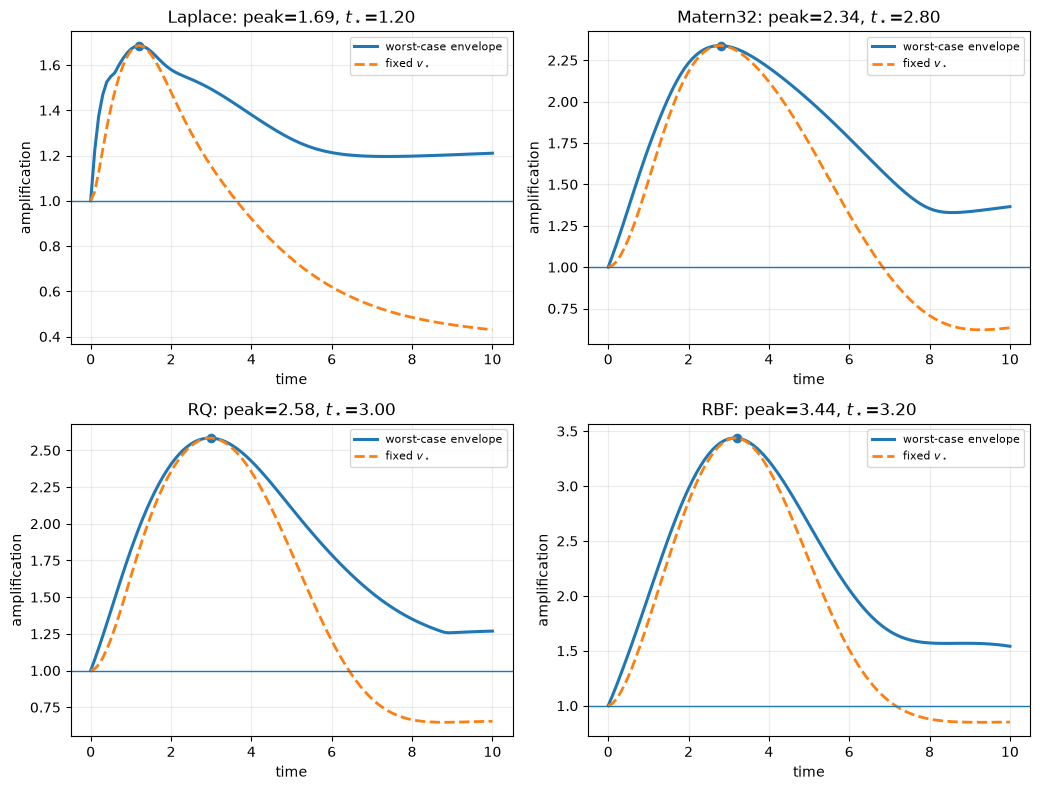

In [13]:

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10.5, 8.0),
)

axes = axes.ravel()

for ax, kind in zip(
    axes,
    KERNELS,
):
    td = models[kind]["transient"]

    ax.plot(
        times,
        td["env"],
        linewidth=2.2,
        label="worst-case envelope",
    )

    ax.plot(
        times,
        td["fixed"],
        linewidth=2.0,
        linestyle="--",
        label=r"fixed $v_\star$",
    )

    ax.axhline(
        1.0,
        linewidth=1.0,
    )

    ax.scatter(
        [td["t_peak"] * DT],
        [td["peak"]],
        s=35,
    )

    ax.set_title(
        f"{kind}: "
        f"peak={td['peak']:.2f}, "
        f"$t_\\star$="
        f"{td['t_peak'] * DT:.2f}"
    )

    ax.set_xlabel("time")
    ax.set_ylabel("amplification")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_fixed_direction_growth.png",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()



## 7. Koopman surrogate pseudospectra and Kreiss estimate

For each normalized KEDMD surrogate,

\[
\sigma_\eta(\widetilde A_\lambda)
=
\left\{
z:
\|(zI-\widetilde A_\lambda)^{-1}\|_2
>
\eta^{-1}
\right\},
\]

and

\[
\widehat{\mathcal K}
=
\max_{|z|>1}
(|z|-1)
\|(zI-\widetilde A_\lambda)^{-1}\|_2.
\]

The plotting cell uses clipping only for the **displayed color scale**, avoiding
artificial white holes while leaving the actual resolvent values unchanged.


In [14]:

def resolvent_grid(
    Atilde,
    grid_lim=GRID_LIM,
    grid_n=GRID_N,
    eps_levels=EPS_LEVELS,
):
    xs = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    ys = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    R = np.empty(
        (grid_n, grid_n),
        dtype=float,
    )

    d = Atilde.shape[0]
    Iden = np.eye(d)

    kreiss_hat = 0.0
    kreiss_location = (
        np.nan + 1j * np.nan
    )

    for iy, yy in enumerate(ys):

        for ix, xx in enumerate(xs):

            z = xx + 1j * yy

            smin = svdvals(
                z * Iden - Atilde
            )[-1]

            resolvent = (
                1.0
                / max(
                    float(smin),
                    1e-14,
                )
            )

            R[iy, ix] = resolvent

            modulus = abs(z)

            if modulus > 1.0:

                value = (
                    (modulus - 1.0)
                    * resolvent
                )

                if value > kreiss_hat:

                    kreiss_hat = value
                    kreiss_location = z

    XX, YY = np.meshgrid(
        xs,
        ys,
    )

    MOD = np.sqrt(
        XX ** 2 + YY ** 2
    )

    boundary = np.zeros_like(
        R,
        dtype=bool,
    )

    boundary[0, :] = True
    boundary[-1, :] = True
    boundary[:, 0] = True
    boundary[:, -1] = True

    radii = {}
    boundary_warning = {}

    for eta in eps_levels:

        mask = (
            R > (1.0 / eta)
        )

        if np.any(mask):

            radii[eta] = float(
                np.max(MOD[mask])
            )

            boundary_warning[eta] = bool(
                np.any(
                    mask & boundary
                )
            )

        else:
            radii[eta] = np.nan
            boundary_warning[eta] = False

    return {
        "xs": xs,
        "ys": ys,
        "R": R,
        "log10_R": np.log10(
            np.maximum(
                R,
                1e-14,
            )
        ),
        "kreiss_hat": float(
            kreiss_hat
        ),
        "kreiss_location": kreiss_location,
        "radii": radii,
        "boundary_warning": boundary_warning,
    }


In [15]:

t0 = time.time()

for kind in KERNELS:

    print(
        f"Computing pseudospectrum for {kind} ..."
    )

    models[kind]["pseudo"] = (
        resolvent_grid(
            models[kind]["Atilde"],
            grid_lim=GRID_LIM,
            grid_n=GRID_N,
            eps_levels=EPS_LEVELS,
        )
    )

print(
    "\nTotal pseudospectral runtime:",
    f"{time.time() - t0:.2f} s",
)


Computing pseudospectrum for Laplace ...
Computing pseudospectrum for Matern32 ...
Computing pseudospectrum for RQ ...
Computing pseudospectrum for RBF ...

Total pseudospectral runtime: 8.00 s


In [21]:
from matplotlib.colors import LinearSegmentedColormap

koopman_purple_luxe = LinearSegmentedColormap.from_list(
    "koopman_purple_luxe",
    [
        "#0d001a",  # black-purple
        "#240046",  # deep violet
        "#3c096c",  # royal purple
        "#5a189a",  # saturated purple
        "#7b2cbf",  # violet
        "#3a86ff",  # electric blue
        "#00b4d8",  # cyan
        "#72efdd",  # aqua
        "#ffb703",  # gold
    ],
    N=256,
)

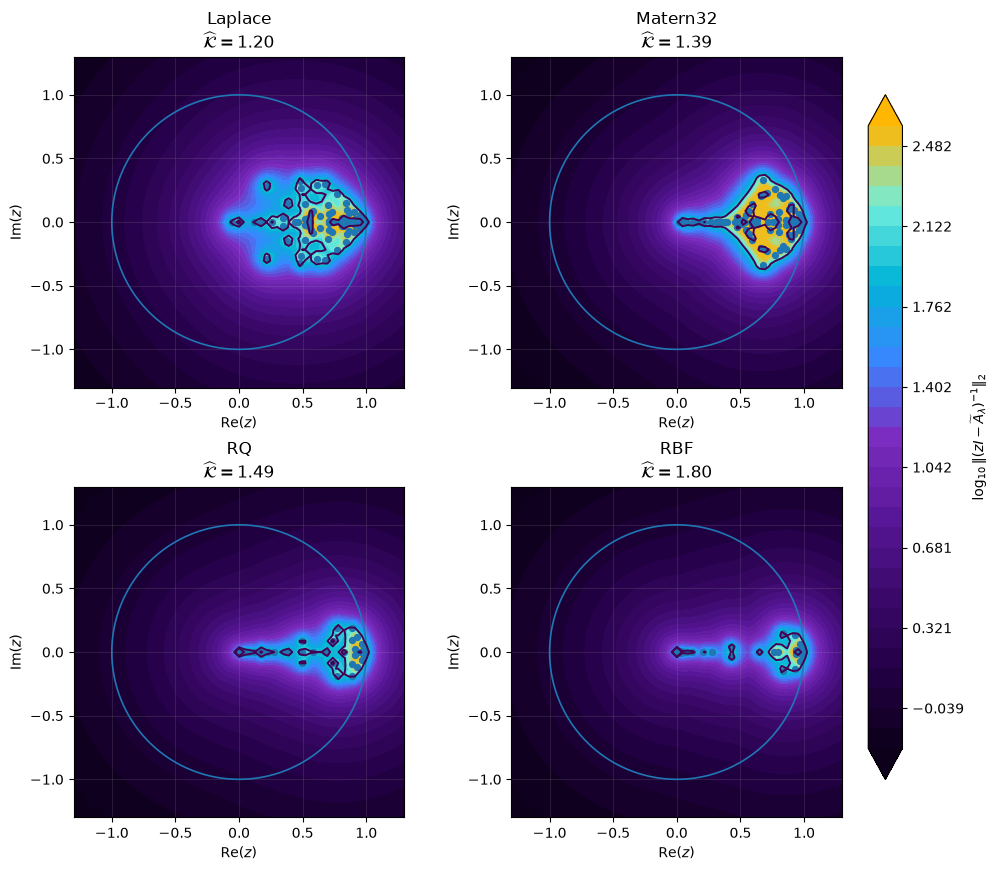

In [23]:

# ------------------------------------------------------------
# Clean common-scale pseudospectral figure
# ------------------------------------------------------------

all_logs = np.concatenate([
    models[k]["pseudo"][
        "log10_R"
    ].ravel()
    for k in KERNELS
])

vmin = float(
    np.percentile(
        all_logs,
        1.0,
    )
)

vmax = float(
    np.percentile(
        all_logs,
        99.0,
    )
)

levels = np.linspace(
    vmin,
    vmax,
    32,
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10.2, 8.6),
    constrained_layout=True,
)

axes = axes.ravel()

theta = np.linspace(
    0.0,
    2.0 * np.pi,
    600,
)

mappable = None

for ax, kind in zip(
    axes,
    KERNELS,
):
    m = models[kind]
    ps = m["pseudo"]

    XX, YY = np.meshgrid(
        ps["xs"],
        ps["ys"],
    )

    Zplot = np.clip(
        ps["log10_R"],
        vmin,
        vmax,
    )

    mappable = ax.contourf(
        XX,
        YY,
        Zplot,
        levels=levels,
        extend="both",
        cmap=koopman_purple_luxe
    )

    eigs = np.linalg.eigvals(
        m["Atilde"]
    )

    ax.scatter(
        np.real(eigs),
        np.imag(eigs),
        s=18,
        zorder=5,
    )

    ax.plot(
        np.cos(theta),
        np.sin(theta),
        linewidth=1.2,
        zorder=4,
    )

    for eta in EPS_LEVELS:

        threshold = np.log10(
            1.0 / eta
        )

        if (
            ps["log10_R"].min()
            <= threshold
            <= ps["log10_R"].max()
        ):

            ax.contour(
                XX,
                YY,
                ps["log10_R"],
                levels=[threshold],
                linewidths=1.4,
                zorder=6,
            )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlim(
        -GRID_LIM,
        GRID_LIM,
    )

    ax.set_ylim(
        -GRID_LIM,
        GRID_LIM,
    )

    ax.set_xlabel(
        r"$\mathrm{Re}(z)$"
    )

    ax.set_ylabel(
        r"$\mathrm{Im}(z)$"
    )

    ax.set_title(
        f"{kind}\n"
        rf"$\widehat{{\mathcal{{K}}}}"
        rf"={ps['kreiss_hat']:.2f}$"
    )

    ax.grid(alpha=0.15)

cbar = fig.colorbar(
    mappable,
    ax=axes.tolist(),
    shrink=0.90,
    pad=0.03,
    extend="both",
)

cbar.set_label(
    r"$\log_{10}"
    r"\|(zI-\widetilde A_\lambda)^{-1}\|_2$"
)

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_KEDMD_pseudospectra_clean.pdf",
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.show()


In [17]:

pseudo_rows = []

for kind in KERNELS:

    m = models[kind]
    td = m["transient"]
    ps = m["pseudo"]

    row = {
        "kernel": kind,
        "gamma": m["gamma"],
        "rho_Atilde": td["rho"],
        "peak_G": td["peak"],
        "t_peak": td["t_peak"],
        "peak_time": td["t_peak"] * DT,
        "Kreiss_hat": ps[
            "kreiss_hat"
        ],
    }

    for eta in EPS_LEVELS:

        row[
            f"r_eps_{eta:.0e}"
        ] = ps["radii"][eta]

        row[
            f"grid_boundary_hit_{eta:.0e}"
        ] = ps[
            "boundary_warning"
        ][eta]

    pseudo_rows.append(row)

pseudospectral_table = (
    pd.DataFrame(
        pseudo_rows
    )
)

display(
    pseudospectral_table
)

pseudospectral_table.to_csv(
    os.path.join(
        OUTDIR,
        "FHN_pseudospectral_summary.csv",
    ),
    index=False,
)


,kernel,gamma,rho_Atilde,peak_G,t_peak,peak_time,Kreiss_hat,r_eps_1e-02,grid_boundary_hit_1e-02,r_eps_1e-03,grid_boundary_hit_1e-03
0,Laplace,0.367711,0.999960,1.685853,12,1.2,1.200275,0.996667,False,0.953333,False
1,Matern32,0.293183,1.000365,2.338868,28,2.8,1.390688,0.997608,False,0.953333,False
2,RQ,0.293183,1.000345,2.583696,30,3.0,1.486108,0.997608,False,0.953333,False
3,RBF,0.293183,1.000606,3.437277,32,3.2,1.795682,0.997608,False,0.953333,False



## 8. Optional local physical tangent pseudospectrum

For context,

\[
F_{\rm local}
=
e^{J_\star\Delta t}
\]

is the exact two-dimensional tangent transition matrix near rest.

Its pseudospectrum is not the same mathematical object as the KEDMD pseudospectrum,
but it provides a controlled physical-state reference.


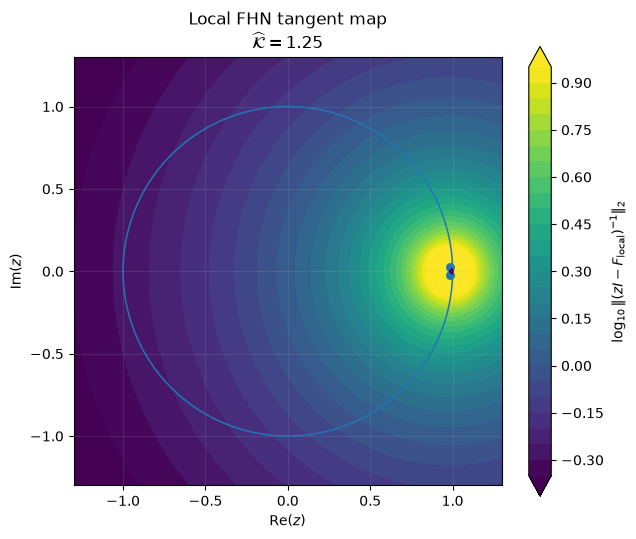

Local physical-state Kreiss estimate = 1.247172816497138
Local physical-state pseudospectral radii = {0.01: 0.9966666666666668, 0.001: nan}


In [18]:

F_local = expm(
    J_star * DT
)

true_ps = resolvent_grid(
    F_local,
    grid_lim=GRID_LIM,
    grid_n=GRID_N,
    eps_levels=EPS_LEVELS,
)

XX, YY = np.meshgrid(
    true_ps["xs"],
    true_ps["ys"],
)

lo = float(
    np.percentile(
        true_ps["log10_R"],
        1.0,
    )
)

hi = float(
    np.percentile(
        true_ps["log10_R"],
        99.0,
    )
)

Zplot = np.clip(
    true_ps["log10_R"],
    lo,
    hi,
)

fig, ax = plt.subplots(
    figsize=(6.5, 5.5),
)

cf = ax.contourf(
    XX,
    YY,
    Zplot,
    levels=30,
    extend="both",
)

ax.scatter(
    np.real(
        np.linalg.eigvals(
            F_local
        )
    ),
    np.imag(
        np.linalg.eigvals(
            F_local
        )
    ),
    s=30,
)

ax.plot(
    np.cos(theta),
    np.sin(theta),
    linewidth=1.1,
)

for eta in EPS_LEVELS:

    threshold = np.log10(
        1.0 / eta
    )

    if (
        true_ps["log10_R"].min()
        <= threshold
        <= true_ps["log10_R"].max()
    ):

        ax.contour(
            XX,
            YY,
            true_ps["log10_R"],
            levels=[threshold],
            linewidths=1.3,
        )

ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.set_xlim(
    -GRID_LIM,
    GRID_LIM,
)

ax.set_ylim(
    -GRID_LIM,
    GRID_LIM,
)

ax.set_xlabel(
    r"$\mathrm{Re}(z)$"
)

ax.set_ylabel(
    r"$\mathrm{Im}(z)$"
)

ax.set_title(
    "Local FHN tangent map\n"
    + rf"$\widehat{{\mathcal{{K}}}}"
    + rf"={true_ps['kreiss_hat']:.2f}$"
)

ax.grid(alpha=0.15)

fig.colorbar(
    cf,
    ax=ax,
    label=(
        r"$\log_{10}"
        r"\|(zI-F_{\rm local})^{-1}\|_2$"
    ),
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_local_physical_pseudospectrum.png",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()

print(
    "Local physical-state Kreiss estimate =",
    true_ps["kreiss_hat"],
)

print(
    "Local physical-state pseudospectral radii =",
    true_ps["radii"],
)



## 9. Regularization sensitivity

The default \(\lambda=3\times10^{-3}\) gives a visible finite-time hierarchy in the
pilot configuration. We therefore explicitly test whether that hierarchy survives
regularization changes rather than treating one value as privileged.


In [19]:

LAMBDA_SWEEP = [
    3e-2,
    1e-2,
    3e-3,
    1e-3,
    3e-4,
]

lambda_rows = []

for lam in LAMBDA_SWEEP:

    for kind in KERNELS:

        m = build_kedmd(
            X,
            Y,
            kind,
            lam=lam,
        )

        td = transient_diagnostics(
            m["Atilde"],
            T=T_TRANSIENT,
        )

        lambda_rows.append({
            "lambda": lam,
            "kernel": kind,
            "cond_Glambda": np.linalg.cond(
                m["Glam"]
            ),
            "rho_Atilde": td["rho"],
            "peak_G": td["peak"],
            "t_peak": td["t_peak"],
            "peak_time": td[
                "t_peak"
            ] * DT,
        })

lambda_table = pd.DataFrame(
    lambda_rows
)

display(
    lambda_table
)

lambda_table.to_csv(
    os.path.join(
        OUTDIR,
        "FHN_lambda_sensitivity.csv",
    ),
    index=False,
)


,lambda,kernel,cond_Glambda,rho_Atilde,peak_G,t_peak,peak_time
0,0.0300,Laplace,662.094351,0.999398,1.299796,9,0.9
1,0.0300,Matern32,1398.658790,0.999996,1.509638,22,2.2
2,0.0300,RQ,1813.780156,0.999887,1.489896,24,2.4
3,0.0300,RBF,1636.654738,1.000296,1.658597,26,2.6
4,0.0100,Laplace,1100.517744,0.999885,1.521723,11,1.1
5,0.0100,Matern32,4152.965126,1.000435,1.847731,23,2.3
6,0.0100,RQ,5439.340368,1.000394,1.863625,25,2.5
7,0.0100,RBF,4907.964213,1.000307,2.114772,26,2.6
8,0.0030,Laplace,1432.873264,0.999960,1.685853,12,1.2
9,0.0030,Matern32,13382.781427,1.000365,2.338868,28,2.8


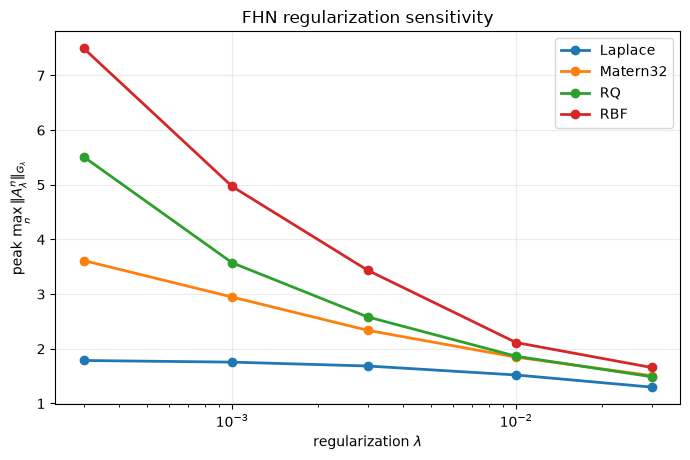

In [26]:

fig, ax = plt.subplots(
    figsize=(7.0, 4.7),
)

for kind in KERNELS:

    d = (
        lambda_table[
            lambda_table["kernel"]
            == kind
        ]
        .sort_values("lambda")
    )

    ax.plot(
        d["lambda"],
        d["peak_G"],
        marker="o",
        linewidth=2.0,
        label=kind,
    )

ax.set_xscale("log")

ax.set_xlabel(
    r"regularization $\lambda$"
)

ax.set_ylabel(
    r"peak "
    r"$\max_n\|A_\lambda^n\|_{G_\lambda}$"
)

ax.set_title(
    "FHN regularization sensitivity"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "FHN_lambda_sensitivity.pdf",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()



# Interpretation

This third experiment gives a distinct neural dynamical regime:

- stable linear E–I: exact population-level control;
- Wilson–Cowan: nonlinear E–I population dynamics;
- FitzHugh–Nagumo: fast–slow excitable single-neuron dynamics.

The strongest cross-system result would be a repeated qualitative pattern such as

\[
\text{Laplace}
<
\text{Matérn}
<
\text{RQ}
<
\text{RBF}
\]

in transient amplification and/or Kreiss sensitivity, while all four surrogates are
trained on exactly the same snapshots for each system.

For the default FHN pilot, expect approximately:

- stable equilibrium;
- local physical peak around \(1.7\);
- Laplace transient around \(1.7\);
- Matérn around \(2.3\)-\(2.6\);
- RQ around \(2.5\)-\(3.0\);
- RBF around \(3.5\)-\(4.0\),

with some variation from implementation and regularization.

Do not use those pilot numbers in a paper; use only the values produced by your actual
saved run.


In [28]:
# ============================================================
# Kreiss grid-resolution convergence experiment
# ============================================================
#
# IMPORTANT:
#   - Do NOT retrain KEDMD.
#   - Do NOT modify Atilde, lambda, gamma, or the snapshots.
#   - We vary ONLY the complex-grid resolution.
#
# Run this cell after the existing models and pseudospectra
# have already been constructed.
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import svdvals


# ------------------------------------------------------------
# CHANGE THESE TWO LINES FOR EACH NOTEBOOK
# ------------------------------------------------------------

#SYSTEM_NAME = "Linear E-I"
#FILE_PREFIX = "EI"

# Wilson-Cowan:
# SYSTEM_NAME = "Wilson-Cowan"
# FILE_PREFIX = "WC"

# FitzHugh-Nagumo:
SYSTEM_NAME = "FitzHugh-Nagumo"
FILE_PREFIX = "FHN"


# ------------------------------------------------------------
# Fixed computational domain
# ------------------------------------------------------------

GRID_LIM_CONV = 1.30

# Nested grids:
# 31 -> 61 -> 121
#
# Keeping 61 is important because it is the grid used for the
# current Table-1 Kreiss values.
GRID_SIZES = [31, 61, 121]


# ============================================================
# Kreiss-only grid calculation
# ============================================================

def kreiss_grid_only(
    Atilde,
    grid_lim=1.30,
    grid_n=61,
):
    """
    Grid-based estimate of the discrete Kreiss constant

        K_hat = max_{z in G, |z| > 1}
                (|z|-1) ||(zI-Atilde)^(-1)||_2.

    This function evaluates only points outside the unit disk,
    because interior points do not enter the Kreiss objective.

    The learned Atilde is kept fixed.
    """

    xs = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    ys = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    d = Atilde.shape[0]

    Iden = np.eye(
        d,
        dtype=complex,
    )

    kreiss_hat = 0.0

    kreiss_location = (
        np.nan + 1j * np.nan
    )

    evaluated_points = 0

    dx = xs[1] - xs[0]
    dy = ys[1] - ys[0]

    for yy in ys:

        for xx in xs:

            z = xx + 1j * yy

            modulus = abs(z)

            # Kreiss objective only requires |z| > 1
            if modulus <= 1.0:
                continue

            evaluated_points += 1

            smin = svdvals(
                z * Iden - Atilde,
                check_finite=False,
            )[-1]

            resolvent = (
                1.0
                / max(
                    float(smin),
                    1e-14,
                )
            )

            value = (
                (modulus - 1.0)
                * resolvent
            )

            if value > kreiss_hat:

                kreiss_hat = value
                kreiss_location = z

    # --------------------------------------------------------
    # Did the maximizer land close to the OUTER box boundary?
    # --------------------------------------------------------

    boundary_tol_x = 0.51 * abs(dx)
    boundary_tol_y = 0.51 * abs(dy)

    outer_boundary_hit = bool(
        (
            abs(kreiss_location.real)
            >= grid_lim - boundary_tol_x
        )
        or
        (
            abs(kreiss_location.imag)
            >= grid_lim - boundary_tol_y
        )
    )

    return {
        "kreiss_hat": float(kreiss_hat),
        "z_star": kreiss_location,
        "abs_z_star": float(
            abs(kreiss_location)
        ),
        "grid_spacing_x": float(dx),
        "grid_spacing_y": float(dy),
        "evaluated_points": int(
            evaluated_points
        ),
        "outer_boundary_hit": (
            outer_boundary_hit
        ),
    }


# ============================================================
# Run grid convergence
# ============================================================

rows = []

total_start = time.time()


for kind in KERNELS:

    Atilde_fixed = models[kind]["Atilde"]

    print("\n" + "=" * 70)
    print(
        f"{SYSTEM_NAME} | {kind}"
    )
    print("=" * 70)

    previous_K = None

    for grid_n in GRID_SIZES:

        start = time.time()

        result = kreiss_grid_only(
            Atilde_fixed,
            grid_lim=GRID_LIM_CONV,
            grid_n=grid_n,
        )

        runtime = (
            time.time() - start
        )

        Khat = result["kreiss_hat"]

        if previous_K is None:

            relative_change = np.nan

        else:

            relative_change = (
                abs(Khat - previous_K)
                / max(abs(Khat), 1e-14)
            )

        rows.append({
            "system": SYSTEM_NAME,
            "kernel": kind,
            "grid_n": grid_n,
            "grid_points_total": (
                grid_n * grid_n
            ),
            "evaluated_exterior_points":
                result[
                    "evaluated_points"
                ],
            "grid_lim": GRID_LIM_CONV,
            "grid_spacing":
                result[
                    "grid_spacing_x"
                ],
            "kreiss_hat": Khat,
            "z_star_real":
                result["z_star"].real,
            "z_star_imag":
                result["z_star"].imag,
            "abs_z_star":
                result["abs_z_star"],
            "outer_boundary_hit":
                result[
                    "outer_boundary_hit"
                ],
            "relative_change_from_previous":
                relative_change,
            "runtime_seconds":
                runtime,
        })

        print(
            f"grid={grid_n:3d} x {grid_n:3d} | "
            f"Khat={Khat:.8f} | "
            f"z*={result['z_star']:.5f} | "
            f"|z*|={result['abs_z_star']:.6f} | "
            f"boundary={result['outer_boundary_hit']} | "
            f"time={runtime:.2f} s"
        )

        previous_K = Khat


total_runtime = (
    time.time() - total_start
)

print(
    "\nTotal grid-convergence runtime = "
    f"{total_runtime:.2f} s"
)


# ============================================================
# Save complete results
# ============================================================

kreiss_conv = pd.DataFrame(rows)

csv_path = os.path.join(
    OUTDIR,
    f"{FILE_PREFIX}_kreiss_grid_convergence.csv",
)

kreiss_conv.to_csv(
    csv_path,
    index=False,
)

print(
    "\nSaved:",
    csv_path,
)

display(kreiss_conv)


FitzHugh-Nagumo | Laplace
grid= 31 x  31 | Khat=1.20027471 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=0.29 s
grid= 61 x  61 | Khat=1.20027471 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=1.06 s
grid=121 x 121 | Khat=1.20027471 | z*=1.12667+0.00000j | |z*|=1.126667 | boundary=False | time=4.05 s

FitzHugh-Nagumo | Matern32
grid= 31 x  31 | Khat=1.39068776 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=0.28 s
grid= 61 x  61 | Khat=1.39068776 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=1.04 s
grid=121 x 121 | Khat=1.39822220 | z*=1.06167+0.00000j | |z*|=1.061667 | boundary=False | time=4.04 s

FitzHugh-Nagumo | RQ
grid= 31 x  31 | Khat=1.48610754 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=0.31 s
grid= 61 x  61 | Khat=1.48610754 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=1.15 s
grid=121 x 121 | Khat=1.48890134 | z*=1.06167+0.00000j | |z*|=1.061667 | boundary=False | time=4.41 s

Fitz

,system,kernel,grid_n,grid_points_total,evaluated_exterior_points,grid_lim,grid_spacing,kreiss_hat,z_star_real,z_star_imag,abs_z_star,outer_boundary_hit,relative_change_from_previous,runtime_seconds
0,FitzHugh-Nagumo,Laplace,31,961,540,1.3,0.086667,1.200275,1.126667,0.0,1.126667,False,NaN,0.287481
1,FitzHugh-Nagumo,Laplace,61,3721,2052,1.3,0.043333,1.200275,1.126667,0.0,1.126667,False,0.000000,1.060544
2,FitzHugh-Nagumo,Laplace,121,14641,7936,1.3,0.021667,1.200275,1.126667,0.0,1.126667,False,0.000000,4.049875
3,FitzHugh-Nagumo,Matern32,31,961,540,1.3,0.086667,1.390688,1.040000,0.0,1.040000,False,NaN,0.278949
4,FitzHugh-Nagumo,Matern32,61,3721,2052,1.3,0.043333,1.390688,1.040000,0.0,1.040000,False,0.000000,1.043538
5,FitzHugh-Nagumo,Matern32,121,14641,7936,1.3,0.021667,1.398222,1.061667,0.0,1.061667,False,0.005389,4.041463
6,FitzHugh-Nagumo,RQ,31,961,540,1.3,0.086667,1.486108,1.040000,0.0,1.040000,False,NaN,0.306121
7,FitzHugh-Nagumo,RQ,61,3721,2052,1.3,0.043333,1.486108,1.040000,0.0,1.040000,False,0.000000,1.153166
8,FitzHugh-Nagumo,RQ,121,14641,7936,1.3,0.021667,1.488901,1.061667,0.0,1.061667,False,0.001876,4.411365
9,FitzHugh-Nagumo,RBF,31,961,540,1.3,0.086667,1.795682,1.040000,0.0,1.040000,False,NaN,0.313727


In [32]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# ============================================================
# FITZHUGH-NAGUMO MECHANISTIC KEDMD SWEEP
#
# Mechanism:
#
#   cond(G_lambda)
#        ->
#   finite-time KEDMD amplification
#        ->
#   voltage-observable correlation response
#
# Produces:
#   FHN_mechanistic_sweep.csv
# ============================================================

import os
import numpy as np
import pandas as pd

from scipy.optimize import root
from scipy.linalg import eigh, solve, svdvals
from scipy.spatial.distance import cdist


# ============================================================
# 0. CONFIGURATION
# ============================================================

SEED = 42

DT = 0.10
N_SUBSTEPS = 8

T_TRANSIENT = 100

# Local state-space sampling around equilibrium
TRAIN_RADIUS = 0.30
M = 80

# Preserve original FHN sensitivity sweep
LAMBDA_SWEEP = [
    3e-2,
    1e-2,
    3e-3,
    1e-3,
    3e-4,
]

KERNELS = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]

# ------------------------------------------------------------
# FHN is slower than E-I.
#
# 40 steps x DT=0.10 gives a 4.0 time-unit window,
# which covers the finite-time transient regime seen in the
# original FHN calculation.
#
# Change to 10 if you explicitly want the exact same
# ten-step window used for E-I.
# ------------------------------------------------------------

CORR_HORIZON = 40

OUTDIR = "FHN_mechanistic_outputs"
os.makedirs(OUTDIR, exist_ok=True)

OUT_CSV = os.path.join(
    OUTDIR,
    "FHN_mechanistic_sweep.csv"
)


# ============================================================
# 1. FITZHUGH-NAGUMO SYSTEM
# ============================================================

a = 0.7
b = 0.8
eps_fhn = 0.08
I_ext = 0.10


def fhn_rhs(x):

    v, w = np.asarray(
        x,
        dtype=float
    )

    dv = (
        v
        - v**3 / 3.0
        - w
        + I_ext
    )

    dw = (
        eps_fhn
        *
        (v + a - b*w)
    )

    return np.array(
        [dv, dw],
        dtype=float
    )


def fhn_rhs_batch(X):

    X = np.asarray(
        X,
        dtype=float
    )

    v = X[:, 0]
    w = X[:, 1]

    dv = (
        v
        - v**3 / 3.0
        - w
        + I_ext
    )

    dw = (
        eps_fhn
        *
        (v + a - b*w)
    )

    return np.column_stack(
        [dv, dw]
    )


def fhn_jacobian(x):

    v, w = np.asarray(
        x,
        dtype=float
    )

    return np.array(
        [
            [1.0 - v**2, -1.0],
            [eps_fhn, -eps_fhn*b],
        ],
        dtype=float
    )


# ============================================================
# 2. STABLE EQUILIBRIUM
# ============================================================

eq_sol = root(
    fhn_rhs,
    x0=np.array(
        [-1.0, -0.5]
    )
)

if not eq_sol.success:
    raise RuntimeError(
        eq_sol.message
    )

x_eq = eq_sol.x

J_star = fhn_jacobian(
    x_eq
)

eig_J = np.linalg.eigvals(
    J_star
)

print(
    "Stable equilibrium x* =",
    x_eq
)

print(
    "Jacobian eigenvalues =",
    eig_J
)

if np.max(
    np.real(eig_J)
) >= 0:

    raise RuntimeError(
        "Selected FHN equilibrium is not asymptotically stable."
    )


# ============================================================
# 3. RK4 FLOW
# ============================================================

def rk4_batch(
    X,
    h
):

    k1 = fhn_rhs_batch(
        X
    )

    k2 = fhn_rhs_batch(
        X + 0.5*h*k1
    )

    k3 = fhn_rhs_batch(
        X + 0.5*h*k2
    )

    k4 = fhn_rhs_batch(
        X + h*k3
    )

    return (
        X
        +
        (h / 6.0)
        *
        (
            k1
            + 2.0*k2
            + 2.0*k3
            + k4
        )
    )


def flow_batch(
    X,
    delta_t=DT,
    n_substeps=N_SUBSTEPS
):

    Y = np.asarray(
        X,
        dtype=float
    ).copy()

    h = (
        delta_t
        /
        n_substeps
    )

    for _ in range(
        n_substeps
    ):

        Y = rk4_batch(
            Y,
            h
        )

    return Y


# ============================================================
# 4. LOCAL SNAPSHOT PAIRS
# ============================================================

rng = np.random.default_rng(
    SEED
)

X = (
    x_eq[None, :]
    +
    rng.uniform(
        -TRAIN_RADIUS,
        TRAIN_RADIUS,
        size=(M, 2)
    )
)

Y = flow_batch(
    X,
    delta_t=DT,
    n_substeps=N_SUBSTEPS
)

# ------------------------------------------------------------
# hard checks
# ------------------------------------------------------------

assert X.shape == (M, 2)
assert Y.shape == (M, 2)

assert np.all(
    np.isfinite(X)
)

assert np.all(
    np.isfinite(Y)
)

print(
    "\nX shape =",
    X.shape
)

print(
    "Y shape =",
    Y.shape
)

print(
    "unique X rows =",
    np.unique(
        X,
        axis=0
    ).shape[0]
)


# ============================================================
# 5. KERNELS
# ============================================================

def pairwise_distance(
    A,
    B,
    metric="euclidean"
):

    A = np.asarray(
        A,
        dtype=float
    )

    B = np.asarray(
        B,
        dtype=float
    )

    if (
        not np.all(
            np.isfinite(A)
        )
        or
        not np.all(
            np.isfinite(B)
        )
    ):

        raise ValueError(
            "Kernel data contain NaN/Inf."
        )

    return cdist(
        A,
        B,
        metric=metric
    )


def safe_median_scale(
    X,
    kind
):

    metric = (
        "cityblock"
        if kind == "Laplace"
        else "euclidean"
    )

    D = pairwise_distance(
        X,
        X,
        metric=metric
    )

    positive = D[
        np.isfinite(D)
        &
        (D > 0.0)
    ]

    if positive.size == 0:

        raise ValueError(
            f"{kind}: no positive pairwise distances."
        )

    gamma = float(
        np.median(
            positive
        )
    )

    if (
        not np.isfinite(gamma)
        or gamma <= 0
    ):

        raise ValueError(
            f"{kind}: invalid gamma={gamma}"
        )

    return gamma


def kernel_matrix(
    A,
    B,
    kind,
    gamma
):

    if kind == "Laplace":

        R = pairwise_distance(
            A,
            B,
            metric="cityblock"
        )

        K = np.exp(
            -R / gamma
        )

    else:

        R = pairwise_distance(
            A,
            B,
            metric="euclidean"
        )

        if kind == "Matern32":

            q = (
                np.sqrt(3.0)
                *
                R
                /
                gamma
            )

            K = (
                (1.0 + q)
                *
                np.exp(-q)
            )

        elif kind == "RQ":

            K = (
                1.0
                +
                R**2
                /
                (2.0*gamma**2)
            ) ** (-1.0)

        elif kind == "RBF":

            K = np.exp(
                -R**2
                /
                (2.0*gamma**2)
            )

        else:

            raise ValueError(
                f"Unknown kernel: {kind}"
            )

    if not np.all(
        np.isfinite(K)
    ):

        raise ValueError(
            f"{kind}: kernel matrix has NaN/Inf."
        )

    return K


print(
    "\nKernel scales:"
)

for kind in KERNELS:

    print(
        f"{kind:10s}",
        safe_median_scale(
            X,
            kind
        )
    )


# ============================================================
# 6. SPD SQUARE ROOT
# ============================================================

def spd_sqrt_and_invsqrt(
    G,
    floor=1e-14
):

    Gs = 0.5 * (
        G + G.T
    )

    evals, U = eigh(
        Gs
    )

    evals = np.maximum(
        evals,
        floor
    )

    Ghalf = (
        U
        *
        np.sqrt(evals)
    ) @ U.T

    Gmhalf = (
        U
        *
        (
            1.0
            /
            np.sqrt(evals)
        )
    ) @ U.T

    return (
        Ghalf,
        Gmhalf
    )


# ============================================================
# 7. KEDMD
#
# Same construction as original FHN notebook:
#
# A = G_lambda^{-1} A_X
#
# Atilde = G_lambda^{-1/2}
#          A_X
#          G_lambda^{-1/2}
# ============================================================

def build_kedmd(
    X,
    Y,
    kind,
    lam
):

    gamma = safe_median_scale(
        X,
        kind
    )

    GX = kernel_matrix(
        X,
        X,
        kind,
        gamma
    )

    AX = kernel_matrix(
        Y,
        X,
        kind,
        gamma
    )

    Glam = (
        GX
        +
        lam
        *
        np.eye(
            GX.shape[0]
        )
    )

    if (
        not np.all(
            np.isfinite(Glam)
        )
        or
        not np.all(
            np.isfinite(AX)
        )
    ):

        raise ValueError(
            f"{kind}, lambda={lam}: "
            "invalid KEDMD matrices."
        )

    A = solve(
        Glam,
        AX,
        assume_a="pos",
        check_finite=True
    )

    Ghalf, Gmhalf = (
        spd_sqrt_and_invsqrt(
            Glam
        )
    )

    Atilde_similarity = (
        Ghalf
        @ A
        @ Gmhalf
    )

    Atilde = (
        Gmhalf
        @ AX
        @ Gmhalf
    )

    identity_error = (
        np.linalg.norm(
            Atilde
            -
            Atilde_similarity,
            ord="fro"
        )
        /
        max(
            np.linalg.norm(
                Atilde,
                ord="fro"
            ),
            1e-16
        )
    )

    return {

        "kind":
            kind,

        "gamma":
            gamma,

        "GX":
            GX,

        "AX":
            AX,

        "Glam":
            Glam,

        "A":
            A,

        "Ghalf":
            Ghalf,

        "Gmhalf":
            Gmhalf,

        "Atilde":
            Atilde,

        "identity_error":
            identity_error,
    }


# ============================================================
# 8. FINITE-TIME KEDMD AMPLIFICATION
# ============================================================

def transient_diagnostics(
    Atilde,
    T
):

    d = Atilde.shape[0]

    env = np.zeros(
        T + 1
    )

    env[0] = 1.0

    P = np.eye(
        d,
        dtype=Atilde.dtype
    )

    for n in range(
        1,
        T + 1
    ):

        P = (
            P
            @ Atilde
        )

        env[n] = float(
            svdvals(P)[0]
        )

    t_peak = int(
        np.argmax(
            env[1:]
        )
        + 1
    )

    peak = float(
        env[
            t_peak
        ]
    )

    rho = float(
        np.max(
            np.abs(
                np.linalg.eigvals(
                    Atilde
                )
            )
        )
    )

    return {

        "env":
            env,

        "peak":
            peak,

        "t_peak":
            t_peak,

        "rho":
            rho,
    }


# ============================================================
# 9. VOLTAGE OBSERVABLE
#
# f(v,w) = v - v*
#
# Using the deviation removes the equilibrium/DC component.
# ============================================================

def voltage_observable(
    X
):

    return (
        X[:, 0]
        -
        x_eq[0]
    ).astype(float)


# ============================================================
# 10. CORRELATION DIAGNOSTIC
#
# C(n) = c* G_lambda A_lambda^n c
#
# where
#
# G_lambda c = f(X)
# ============================================================

def correlation_diagnostics(
    model,
    X,
    T
):

    Glam = model[
        "Glam"
    ]

    A = model[
        "A"
    ]

    fX = voltage_observable(
        X
    )

    coeff = solve(
        Glam,
        fX,
        assume_a="pos",
        check_finite=True
    )

    C0 = np.vdot(
        coeff,
        Glam @ coeff
    )

    C0_abs = max(
        float(
            np.abs(
                C0
            )
        ),
        1e-16
    )

    C = np.zeros(
        T + 1,
        dtype=np.complex128
    )

    C[0] = C0

    P = np.eye(
        A.shape[0],
        dtype=A.dtype
    )

    for n in range(
        1,
        T + 1
    ):

        P = (
            P
            @ A
        )

        C[n] = np.vdot(
            coeff,
            Glam @ (
                P @ coeff
            )
        )

    C_abs = np.abs(
        C
    )

    C_rel = (
        C_abs
        /
        C0_abs
    )

    # exclude n = 0
    t_peak = int(
        np.argmax(
            C_abs[1:]
        )
        + 1
    )

    t_peak_rel = int(
        np.argmax(
            C_rel[1:]
        )
        + 1
    )

    return {

        "C":
            C,

        "C_abs":
            C_abs,

        "C_rel":
            C_rel,

        "C0":
            float(
                np.real(
                    C0
                )
            ),

        "corr_peak":
            float(
                C_abs[
                    t_peak
                ]
            ),

        "corr_t_peak":
            t_peak,

        "corr_peak_rel":
            float(
                C_rel[
                    t_peak_rel
                ]
            ),

        "corr_t_peak_rel":
            t_peak_rel,
    }


# ============================================================
# 11. COMPLETE MECHANISTIC SWEEP
# ============================================================

rows = []

for lam in LAMBDA_SWEEP:

    print(
        "\n====================================="
    )

    print(
        f"lambda = {lam:.1e}"
    )

    for kind in KERNELS:

        model = build_kedmd(
            X,
            Y,
            kind,
            lam
        )

        td = transient_diagnostics(
            model["Atilde"],
            T=T_TRANSIENT
        )

        cd = correlation_diagnostics(
            model,
            X,
            T=CORR_HORIZON
        )

        cond_G = float(
            np.linalg.cond(
                model["Glam"]
            )
        )

        # one-step induced norm
        opnorm_G = float(
            svdvals(
                model["Atilde"]
            )[0]
        )

        row = {

            "system":
                "FitzHugh-Nagumo",

            "lambda":
                lam,

            "kernel":
                kind,

            "gamma":
                model["gamma"],

            "cond_Glambda":
                cond_G,

            "rho_Atilde":
                td["rho"],

            "opnorm_G":
                opnorm_G,

            "peak_G":
                td["peak"],

            "t_peak":
                td["t_peak"],

            "peak_time":
                td["t_peak"] * DT,

            "corr_C0":
                cd["C0"],

            "corr_peak":
                cd["corr_peak"],

            "corr_t_peak":
                cd["corr_t_peak"],

            "corr_peak_time":
                cd["corr_t_peak"] * DT,

            "corr_peak_rel":
                cd["corr_peak_rel"],

            "corr_t_peak_rel":
                cd["corr_t_peak_rel"],

            "identity_error":
                model["identity_error"],
        }

        rows.append(
            row
        )

        print(
            f"{kind:10s}"
            f" | gamma={model['gamma']:.5f}"
            f" | cond={cond_G:.3e}"
            f" | peak_G={td['peak']:.4f}"
            f" | corr_peak={cd['corr_peak']:.4e}"
        )


# ============================================================
# 12. SAVE
# ============================================================

df = pd.DataFrame(
    rows
)

print(
    "\n========== FHN MECHANISTIC TABLE =========="
)

print(
    df[
        [
            "kernel",
            "lambda",
            "cond_Glambda",
            "rho_Atilde",
            "peak_G",
            "peak_time",
            "corr_peak",
            "corr_peak_time",
        ]
    ].to_string(
        index=False
    )
)

df.to_csv(
    OUT_CSV,
    index=False
)

print(
    "\nSaved:"
)

print(
    OUT_CSV
)

Stable equilibrium x* = [-1.137512 -0.54689 ]
Jacobian eigenvalues = [-0.178967+0.258423j -0.178967-0.258423j]

X shape = (80, 2)
Y shape = (80, 2)
unique X rows = 80

Kernel scales:
Laplace    0.3677109378849332
Matern32   0.29318289473513715
RQ         0.29318289473513715
RBF        0.29318289473513715

lambda = 3.0e-02
Laplace    | gamma=0.36771 | cond=6.621e+02 | peak_G=1.2998 | corr_peak=2.9662e-01
Matern32   | gamma=0.29318 | cond=1.399e+03 | peak_G=1.5096 | corr_peak=2.8801e-01
RQ         | gamma=0.29318 | cond=1.814e+03 | peak_G=1.4899 | corr_peak=3.4758e-01
RBF        | gamma=0.29318 | cond=1.637e+03 | peak_G=1.6586 | corr_peak=3.2493e-01

lambda = 1.0e-02
Laplace    | gamma=0.36771 | cond=1.101e+03 | peak_G=1.5217 | corr_peak=3.0235e-01
Matern32   | gamma=0.29318 | cond=4.153e+03 | peak_G=1.8477 | corr_peak=3.0840e-01
RQ         | gamma=0.29318 | cond=5.439e+03 | peak_G=1.8636 | corr_peak=3.8405e-01
RBF        | gamma=0.29318 | cond=4.908e+03 | peak_G=2.1148 | corr_peak=3.745


FHN empirical dynamical Pareto set:
  kernel  lambda   peak_G  corr_peak
 Laplace    0.03 1.299796   0.296615
Matern32    0.03 1.509638   0.288010

FHN numerical Pareto set:
 kernel  lambda  cond_Glambda   peak_G
Laplace    0.03    662.094351 1.299796


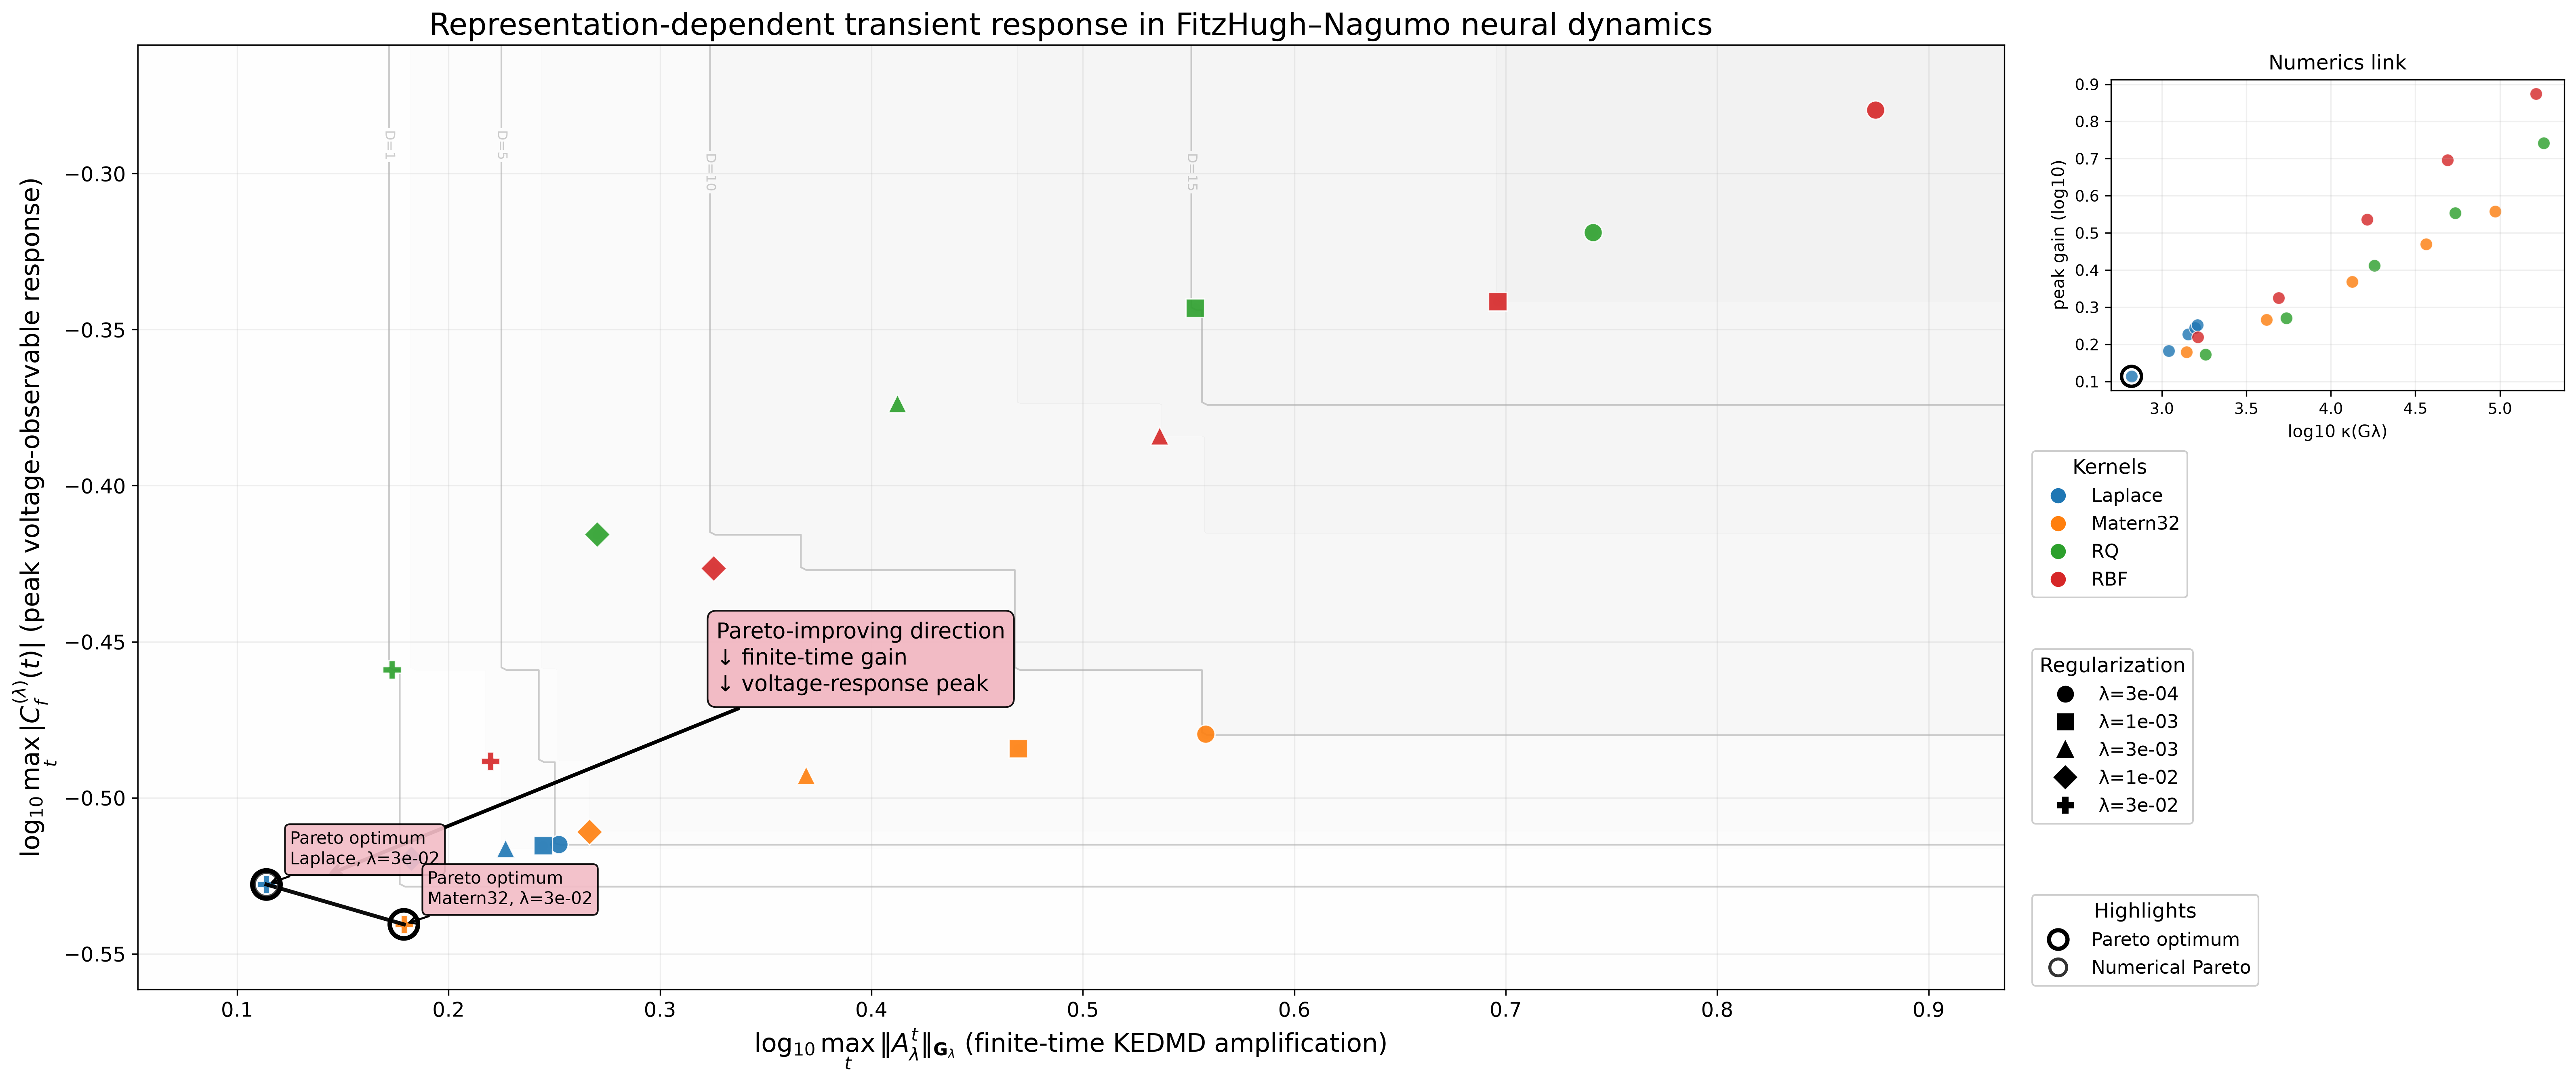


Saved:
FHN_mechanistic_outputs/FHN_pareto_dominance_neurreps.png
FHN_mechanistic_outputs/FHN_pareto_dominance_neurreps.pdf


In [37]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# ============================================================
# FITZHUGH-NAGUMO PARETO-DOMINANCE FIGURE
#
# Input:
#   FHN_mechanistic_sweep.csv
#
# Main plane:
#   x = log10 peak finite-time KEDMD gain
#   y = log10 peak voltage-observable response
#
# Inset:
#   x = log10 cond(G_lambda)
#   y = log10 peak finite-time gain
#
# Dominance contours:
#   D(x,y) = number of sampled configurations
#            dominating location (x,y)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# ============================================================
# 0. PATHS
# ============================================================

OUTDIR = "FHN_mechanistic_outputs"

CSV_PATH = os.path.join(
    OUTDIR,
    "FHN_mechanistic_sweep.csv"
)

OUT_PNG = os.path.join(
    OUTDIR,
    "FHN_pareto_dominance_neurreps.png"
)

OUT_PDF = os.path.join(
    OUTDIR,
    "FHN_pareto_dominance_neurreps.pdf"
)


# ============================================================
# 1. PARETO UTILITIES
# ============================================================

def pareto_mask_min2(
    x,
    y
):

    x = np.asarray(
        x
    )

    y = np.asarray(
        y
    )

    n = len(
        x
    )

    keep = np.ones(
        n,
        dtype=bool
    )

    for i in range(
        n
    ):

        dominates_i = (
            (x <= x[i])
            &
            (y <= y[i])
            &
            (
                (x < x[i])
                |
                (y < y[i])
            )
        )

        dominates_i[i] = False

        if np.any(
            dominates_i
        ):

            keep[i] = False

    return keep


def dominance_field(
    x_data,
    y_data,
    x_grid,
    y_grid
):

    XX, YY = np.meshgrid(
        x_grid,
        y_grid
    )

    D = np.zeros_like(
        XX,
        dtype=float
    )

    for xi, yi in zip(
        x_data,
        y_data
    ):

        D += (
            (xi <= XX)
            &
            (yi <= YY)
        )

    return (
        XX,
        YY,
        D
    )


# ============================================================
# 2. LOAD DATA
# ============================================================

df = pd.read_csv(
    CSV_PATH
)

required = [
    "kernel",
    "lambda",
    "cond_Glambda",
    "peak_G",
    "corr_peak",
]

missing = [
    c
    for c in required
    if c not in df.columns
]

if missing:

    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Found: {df.columns.tolist()}"
    )


# ============================================================
# 3. LOG OBJECTIVE COORDINATES
# ============================================================

tiny = 1e-16

df["logCond"] = np.log10(
    np.maximum(
        df["cond_Glambda"],
        tiny
    )
)

df["logGain"] = np.log10(
    np.maximum(
        df["peak_G"],
        tiny
    )
)

df["logCorr"] = np.log10(
    np.maximum(
        df["corr_peak"],
        tiny
    )
)


# ============================================================
# 4. PARETO SETS
# ============================================================

# main dynamical Pareto relation
df["pareto_dyn"] = pareto_mask_min2(
    df["logGain"],
    df["logCorr"]
)

# numerical Pareto relation
df["pareto_num"] = pareto_mask_min2(
    df["logCond"],
    df["logGain"]
)

pareto_dyn = (
    df[
        df["pareto_dyn"]
    ]
    .sort_values(
        "logGain"
    )
    .copy()
)

pareto_num = (
    df[
        df["pareto_num"]
    ]
    .sort_values(
        "logCond"
    )
    .copy()
)


print(
    "\nFHN empirical dynamical Pareto set:"
)

print(
    pareto_dyn[
        [
            "kernel",
            "lambda",
            "peak_G",
            "corr_peak",
        ]
    ].to_string(
        index=False
    )
)

print(
    "\nFHN numerical Pareto set:"
)

print(
    pareto_num[
        [
            "kernel",
            "lambda",
            "cond_Glambda",
            "peak_G",
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 5. STYLE
#
# no custom mathtext font setting
# ============================================================

plt.rcParams.update({

    "text.usetex":
        False,

    "font.family":
        "DejaVu Sans",

    "font.size":
        12,

    "axes.titlesize":
        18,

    "axes.labelsize":
        15,

    "xtick.labelsize":
        12,

    "ytick.labelsize":
        12,

    "legend.fontsize":
        11,

    "pdf.fonttype":
        42,

    "ps.fonttype":
        42,
})


kernel_order = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]

kernel_color = {

    "Laplace":
        "#1f77b4",

    "Matern32":
        "#ff7f0e",

    "RQ":
        "#2ca02c",

    "RBF":
        "#d62728",
}


# ------------------------------------------------------------
# Marker mapping automatically follows the five native FHN
# regularization levels.
# ------------------------------------------------------------

lambda_order = sorted(
    df["lambda"].unique()
)

marker_cycle = [
    "o",
    "s",
    "^",
    "D",
    "P",
    "X",
    "v",
]

lambda_marker = {

    lam:
        marker_cycle[
            i
            %
            len(marker_cycle)
        ]

    for i, lam
    in enumerate(
        lambda_order
    )
}


# ============================================================
# 6. DOMINANCE FIELD
# ============================================================

x_data = df[
    "logGain"
].to_numpy()

y_data = df[
    "logCorr"
].to_numpy()


x_span = max(
    x_data.max()
    -
    x_data.min(),
    1e-6
)

y_span = max(
    y_data.max()
    -
    y_data.min(),
    1e-6
)


x_grid = np.linspace(
    x_data.min()
    -
    0.08*x_span,

    x_data.max()
    +
    0.08*x_span,

    350
)

y_grid = np.linspace(
    y_data.min()
    -
    0.08*y_span,

    y_data.max()
    +
    0.08*y_span,

    350
)


XX, YY, D = dominance_field(
    x_data,
    y_data,
    x_grid,
    y_grid
)


# ============================================================
# Adaptive dominance contour levels
# ============================================================

N = len(
    df
)

candidate_levels = [
    1,
    int(
        np.ceil(
            0.25*N
        )
    ),
    int(
        np.ceil(
            0.50*N
        )
    ),
    int(
        np.ceil(
            0.75*N
        )
    ),
]

dominance_levels = sorted(
    set(
        [
            v
            for v
            in candidate_levels
            if 0 < v < N
        ]
    )
)


# ============================================================
# 7. FIGURE
# ============================================================

fig = plt.figure(
    figsize=(22.0, 9.5),
    dpi=300
)


# main panel
ax = fig.add_axes(
    [
        0.07,
        0.10,
        0.70,
        0.82
    ]
)


# inset
ax_in = fig.add_axes(
    [
        0.81,
        0.62,
        0.17,
        0.27
    ]
)


# ============================================================
# 8. PARETO-DOMINANCE BACKGROUND
# ============================================================

# subtle filled dominance regions
fill_levels = np.linspace(
    -0.5,
    N + 0.5,
    7
)

ax.contourf(
    XX,
    YY,
    D,

    levels=
        fill_levels,

    cmap=
        "Greys",

    alpha=
        0.055,

    zorder=
        0
)


# dominance lines
if len(
    dominance_levels
) > 0:

    CS = ax.contour(
        XX,
        YY,
        D,

        levels=
            dominance_levels,

        colors=
            "#7d7d7d",

        linewidths=
            1.0,

        alpha=
            0.38,

        zorder=
            1
    )

    fmt = {
        level:
            f"D={level}"
        for level
        in dominance_levels
    }

    ax.clabel(
        CS,

        inline=
            True,

        fontsize=
            8,

        fmt=
            fmt
    )


# ============================================================
# 9. FAINT DATA CLOUD
# ============================================================

ax.scatter(
    df["logGain"],
    df["logCorr"],

    s=
        35,

    color=
        "lightgray",

    alpha=
        0.25,

    linewidths=
        0,

    zorder=
        2
)


# ============================================================
# 10. KERNEL / REGULARIZATION POINTS
# ============================================================

for kind in kernel_order:

    dk = df[
        df["kernel"]
        ==
        kind
    ]

    for lam in lambda_order:

        dkl = dk[
            np.isclose(
                dk["lambda"],
                lam
            )
        ]

        if dkl.empty:
            continue

        ax.scatter(
            dkl["logGain"],
            dkl["logCorr"],

            s=
                120,

            marker=
                lambda_marker[
                    lam
                ],

            color=
                kernel_color[
                    kind
                ],

            edgecolors=
                "white",

            linewidths=
                0.8,

            alpha=
                0.90,

            zorder=
                4
        )


# ============================================================
# 11. EMPIRICAL DYNAMICAL PARETO SET
# ============================================================

if len(
    pareto_dyn
) > 1:

    ax.plot(
        pareto_dyn[
            "logGain"
        ],
        pareto_dyn[
            "logCorr"
        ],

        color=
            "black",

        linewidth=
            2.3,

        alpha=
            0.95,

        zorder=
            6
    )


ax.scatter(
    pareto_dyn[
        "logGain"
    ],

    pareto_dyn[
        "logCorr"
    ],

    s=
        280,

    facecolors=
        "none",

    edgecolors=
        "black",

    linewidths=
        2.7,

    zorder=
        7
)


# ============================================================
# 12. NUMERICAL-PARETO RINGS
# ============================================================

ax.scatter(
    pareto_num[
        "logGain"
    ],

    pareto_num[
        "logCorr"
    ],

    s=
        205,

    facecolors=
        "none",

    edgecolors=
        "#333333",

    linewidths=
        1.8,

    alpha=
        0.90,

    zorder=
        6
)


# ============================================================
# 13. LABEL TRUE PARETO CONFIGURATION(S)
# ============================================================

for _, row in pareto_dyn.iterrows():

    label = (
        "Pareto optimum\n"
        +
        f"{row['kernel']}, "
        +
        f"λ={row['lambda']:.0e}"
    )

    ax.annotate(

        label,

        (
            row[
                "logGain"
            ],
            row[
                "logCorr"
            ]
        ),

        xytext=
            (14, 12),

        textcoords=
            "offset points",

        fontsize=
            10,

        bbox=dict(

            boxstyle=
                "round,pad=0.30",

            facecolor=
                "#f3bdc7",

            edgecolor=
                "black",

            alpha=
                0.92
        ),

        arrowprops=dict(

            arrowstyle=
                "->",

            linewidth=
                1.2,

            color=
                "black"
        ),

        zorder=
            10
    )


# ============================================================
# 14. PARETO-IMPROVING DIRECTION
# ============================================================

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()


ax.annotate(

    "Pareto-improving direction\n"
    "↓ finite-time gain\n"
    "↓ voltage-response peak",

    xy=(
        xmin
        +
        0.10
        *
        (xmax - xmin),

        ymin
        +
        0.12
        *
        (ymax - ymin)
    ),

    xytext=(
        xmin
        +
        0.31
        *
        (xmax - xmin),

        ymin
        +
        0.35
        *
        (ymax - ymin)
    ),

    fontsize=
        13,

    ha=
        "left",

    va=
        "center",

    bbox=dict(

        boxstyle=
            "round,pad=0.40",

        facecolor=
            "#f2b6c1",

        edgecolor=
            "black",

        alpha=
            0.92
    ),

    arrowprops=dict(

        arrowstyle=
            "->",

        linewidth=
            2.2,

        color=
            "black"
    ),

    zorder=
        9
)


# ============================================================
# 15. MAIN AXIS
# ============================================================

ax.set_xlabel(
    r"$\log_{10}\max_t\|A_\lambda^t\|_{\mathbf{G}_\lambda}$ (finite-time KEDMD amplification)"
)

ax.set_ylabel(
    r"$\log_{10}\max_t |C_f^{(\lambda)}(t)|$ (peak voltage-observable response)"
)

ax.set_title(
    "Representation-dependent transient response "
    "in FitzHugh–Nagumo neural dynamics"
)

ax.grid(
    alpha=0.20
)


# ============================================================
# 16. NUMERICS-LINK INSET
# ============================================================

ax_in.scatter(
    df["logCond"],
    df["logGain"],

    s=
        40,

    color=
        "lightgray",

    alpha=
        0.22,

    linewidths=
        0
)


for kind in kernel_order:

    dk = df[
        df["kernel"]
        ==
        kind
    ]

    ax_in.scatter(

        dk[
            "logCond"
        ],

        dk[
            "logGain"
        ],

        s=
            55,

        color=
            kernel_color[
                kind
            ],

        alpha=
            0.80,

        edgecolors=
            "white",

        linewidths=
            0.5
    )


# numerical Pareto in inset
ax_in.scatter(

    pareto_num[
        "logCond"
    ],

    pareto_num[
        "logGain"
    ],

    s=
        140,

    facecolors=
        "none",

    edgecolors=
        "black",

    linewidths=
        2.0,

    zorder=
        6
)


ax_in.set_title(
    "Numerics link",
    fontsize=12
)

ax_in.set_xlabel(
    "log10 κ(Gλ)",
    fontsize=10
)

ax_in.set_ylabel(
    "peak gain (log10)",
    fontsize=10
)

ax_in.tick_params(
    labelsize=9
)

ax_in.grid(
    alpha=0.20
)


# ============================================================
# 17. LEGENDS
# ============================================================

kernel_handles = [

    Line2D(

        [0],
        [0],

        marker=
            "o",

        linestyle=
            "None",

        markerfacecolor=
            kernel_color[
                kind
            ],

        markeredgecolor=
            "white",

        markersize=
            10,

        label=
            kind
    )

    for kind
    in kernel_order
]


lambda_handles = [

    Line2D(

        [0],
        [0],

        marker=
            lambda_marker[
                lam
            ],

        linestyle=
            "None",

        color=
            "black",

        markersize=
            9,

        label=
            f"λ={lam:.0e}"
    )

    for lam
    in lambda_order
]


highlight_handles = [

    Line2D(

        [0],
        [0],

        marker=
            "o",

        linestyle=
            "None",

        markerfacecolor=
            "none",

        markeredgecolor=
            "black",

        markeredgewidth=
            2.5,

        markersize=
            11,

        label=
            "Pareto optimum"
    ),

    Line2D(

        [0],
        [0],

        marker=
            "o",

        linestyle=
            "None",

        markerfacecolor=
            "none",

        markeredgecolor=
            "#333333",

        markeredgewidth=
            1.8,

        markersize=
            10,

        label=
            "Numerical Pareto"
    ),
]


leg1 = ax.legend(

    handles=
        kernel_handles,

    title=
        "Kernels",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.01, 0.58),

    framealpha=
        0.95
)

ax.add_artist(
    leg1
)


leg2 = ax.legend(

    handles=
        lambda_handles,

    title=
        "Regularization",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.01, 0.37),

    framealpha=
        0.95
)

ax.add_artist(
    leg2
)


ax.legend(

    handles=
        highlight_handles,

    title=
        "Highlights",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.01, 0.11),

    framealpha=
        0.95
)


# ============================================================
# 18. SAVE
# ============================================================

fig.savefig(
    OUT_PNG,
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUT_PDF,
    bbox_inches="tight"
)

plt.show()


print(
    "\nSaved:"
)

print(
    OUT_PNG
)

print(
    OUT_PDF
)

In [29]:
# ============================================================
# Compact convergence table
# ============================================================

kreiss_pivot = kreiss_conv.pivot(
    index="grid_n",
    columns="kernel",
    values="kreiss_hat",
)

print(
    f"\n{SYSTEM_NAME}: Kreiss grid convergence"
)

display(
    kreiss_pivot.round(6)
)


FitzHugh-Nagumo: Kreiss grid convergence


kernel,Laplace,Matern32,RBF,RQ
grid_n,,,,
31,1.200275,1.390688,1.795682,1.486108
61,1.200275,1.390688,1.795682,1.486108
121,1.200275,1.398222,1.795682,1.488901


In [30]:
# ============================================================
# Relative change: 61^2 -> 121^2
# ============================================================

comparison_rows = []

for kind in KERNELS:

    sub = kreiss_conv[
        kreiss_conv["kernel"] == kind
    ].set_index("grid_n")

    K61 = float(
        sub.loc[61, "kreiss_hat"]
    )

    K121 = float(
        sub.loc[121, "kreiss_hat"]
    )

    percent_change = (
        100.0
        * abs(K121 - K61)
        / max(abs(K121), 1e-14)
    )

    comparison_rows.append({
        "system": SYSTEM_NAME,
        "kernel": kind,
        "K_61": K61,
        "K_121": K121,
        "percent_change_61_to_121":
            percent_change,
        "ordering_stable":
            True,   # updated below
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


# Check whether kernel ordering is unchanged
order_61 = list(
    kreiss_conv[
        kreiss_conv["grid_n"] == 61
    ]
    .sort_values("kreiss_hat")["kernel"]
)

order_121 = list(
    kreiss_conv[
        kreiss_conv["grid_n"] == 121
    ]
    .sort_values("kreiss_hat")["kernel"]
)

same_order = (
    order_61 == order_121
)

comparison_df[
    "ordering_stable"
] = same_order


print(
    "\nOrdering at 61x61 :",
    " < ".join(order_61),
)

print(
    "Ordering at 121x121:",
    " < ".join(order_121),
)

print(
    "Ordering preserved:",
    same_order,
)

display(
    comparison_df.round(6)
)


comparison_df.to_csv(
    os.path.join(
        OUTDIR,
        f"{FILE_PREFIX}_kreiss_grid_61_vs_121.csv",
    ),
    index=False,
)


Ordering at 61x61 : Laplace < Matern32 < RQ < RBF
Ordering at 121x121: Laplace < Matern32 < RQ < RBF
Ordering preserved: True


,system,kernel,K_61,K_121,percent_change_61_to_121,ordering_stable
0,FitzHugh-Nagumo,Laplace,1.200275,1.200275,0.000000,True
1,FitzHugh-Nagumo,Matern32,1.390688,1.398222,0.538859,True
2,FitzHugh-Nagumo,RQ,1.486108,1.488901,0.187642,True
3,FitzHugh-Nagumo,RBF,1.795682,1.795682,0.000000,True


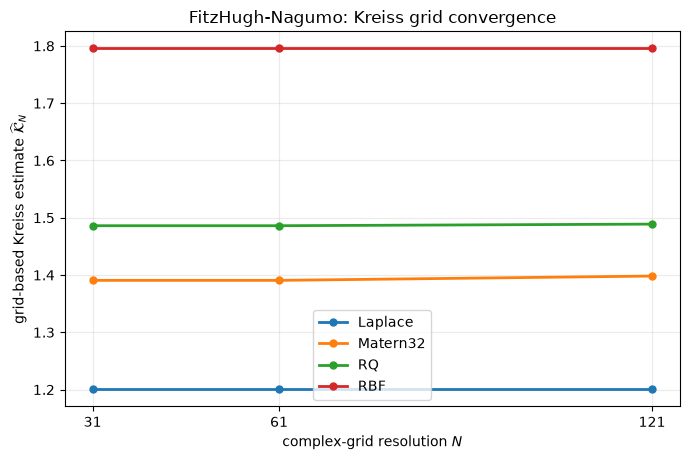

Saved: FHN_kernel_koopman_results/FHN_kreiss_grid_convergence.pdf


In [31]:
# ============================================================
# Kreiss grid-convergence figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.0, 4.7)
)

for kind in KERNELS:

    sub = (
        kreiss_conv[
            kreiss_conv["kernel"] == kind
        ]
        .sort_values("grid_n")
    )

    ax.plot(
        sub["grid_n"],
        sub["kreiss_hat"],
        marker="o",
        linewidth=2.0,
        markersize=5,
        label=kind,
    )


ax.set_xlabel(
    "complex-grid resolution $N$"
)

ax.set_ylabel(
    r"grid-based Kreiss estimate "
    r"$\widehat{\mathcal{K}}_N$"
)

ax.set_title(
    f"{SYSTEM_NAME}: Kreiss grid convergence"
)

ax.set_xticks(
    GRID_SIZES
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=True
)

plt.tight_layout()

figure_path = os.path.join(
    OUTDIR,
    f"{FILE_PREFIX}_kreiss_grid_convergence.pdf",
)

plt.savefig(
    figure_path,
    dpi=500,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    figure_path,
)